# AirGuard India — Phase 3: Modelling, Comparison and Product

**AD23532 · Principles of Data Science**
Rajalakshmi Engineering College (Autonomous, affiliated to Anna University, Chennai)

| | |
| --- | --- |
| Phase | 3 of 3 — Review 3 |
| Rubric rows addressed | Model implementation; evaluation metrics; performance comparison; tuning; product development |
| Degree and branch | B.Tech. Artificial Intelligence and Data Science |
| Regulation / Year / Semester | 2023 / 2026-27 (ODD) / V |
| Team | 260586 (Nishanth Rajendran), 260598 (<NAME>), 260600 (<NAME>) |
| Repository | https://github.com/nishaids/airguard-india |

---

> **How to read this notebook.** It contains orchestration and narrative only.
> Every piece of analysis logic lives in the `src/` package and is imported
> here, so nothing shown below can drift away from the code that produced the
> committed results. Every number displayed is read from `results/*.json`, which
> the pipeline writes; none is typed by hand.


In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import config

config.set_global_seed()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RESULTS = config.RESULTS_DIR
FIGURES = config.FIGURES_DIR

def load(name: str) -> dict:
    """Load a results artefact by file name."""
    path = RESULTS / name
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}

def show(filename: str, caption: str = "") -> None:
    """Display a pipeline-generated figure with its caption."""
    path = FIGURES / filename
    if path.exists():
        display(Image(filename=str(path), width=900))
        if caption:
            display(Markdown(f"*{caption}*"))
    else:
        display(Markdown(f"> Figure `{filename}` not found. Run `python run_all.py`."))

print(f"Project root: {ROOT}")
print(f"Global seed:  {config.RANDOM_SEED}")


Project root: D:\PODS Project\airguard-india
Global seed:  42


## 1. The formulation, and why it matters

Every model predicts **tomorrow** from information available **today**. That choice makes the output actionable, and it also dissolves a leakage problem that a same-day formulation suffers from. The experiment below measures the difference rather than asserting it.

In [2]:
classification = load("evaluation_classification.json")
leak = classification["leakage_demonstration"]
display(pd.DataFrame([
    {
        "Setup": key.replace("_", " "),
        "Macro F1": leak[key]["macro_f1"],
        "Accuracy": leak[key]["accuracy"],
        "Features": leak[key]["n_features"],
    }
    for key in ("same_day_nowcast_with_aqi", "same_day_nowcast_without_aqi",
                "next_day_forecast_this_project")
]))
display(Markdown(f"> {leak['conclusion']}"))

,Setup,Macro F1,Accuracy,Features
0,same day nowcast with aqi,1.0000,1.0000,103
1,same day nowcast without aqi,0.9666,0.9770,100
2,next day forecast this project,0.7077,0.7785,102


> Predicting the same day's bucket with same-day AQI present yields a macro-F1 of 1.0000. A score at or near 1.0 is not a result; it is the signature of a model reading its own label, because the CPCB bucket is a deterministic step function of the AQI. The more instructive finding is what happens after the obvious culprits are removed: dropping AQI, the CPCB sub-indices and every HAI column still leaves macro-F1 at 0.9666. The leak is therefore not confined to a single column that a diligent analyst could blacklist. The AQI is by definition the maximum sub-index, and each sub-index is a fixed piecewise-linear function of a pollutant concentration, so the *concentrations themselves* determine the label exactly. Same-day bucket prediction is arithmetic dressed as machine learning, and no choice of feature filter rescues it. That is the reason this project does not attempt it. Forecasting the next day changes the problem substantively: tomorrow's bucket is genuinely unknown today, today's AQI becomes legitimate information rather than a restatement of the answer, and the achieved macro-F1 of 0.7077 measures real predictive skill. The gap between 0.9666 and 0.7077 is the difference between recomputing a known quantity and forecasting an unknown one.

## 2. Regression: next-day AQI

The persistence baseline — tomorrow equals today — is the row that makes every other row interpretable. Daily AQI is strongly autocorrelated, so most of a high R-squared is available for nothing.

In [3]:
regression = load("evaluation_regression.json")
display(Markdown(f"**Primary metric.** {regression['primary_metric_justification']}"))
table = pd.read_csv(RESULTS / "master_comparison_regression.csv")
display(table)
display(Markdown(f"> {regression['baseline_comparison']['verdict']}"))

**Primary metric.** Mean absolute error is the primary regression metric. The AQI distribution is strongly right-skewed (skewness above 2), so RMSE is dominated by a small number of extreme days and would rank models largely by their behaviour on that tail. MAE is in the same units as the target, is directly interpretable as 'the typical miss in AQI points', and treats every day's error proportionally. RMSE, R-squared and MAPE are reported alongside it, and the tail behaviour that RMSE emphasises is examined separately through the residual analysis and the per-band error breakdown.

,Model,Family,CV MAE,CV MAE sd,Test MAE,Test RMSE,Test R2,Test MAPE %,Test bias,Train MAE,Train-test R2 gap,Fit seconds
0,LightGBM,gradient boosting,29.9257,9.9545,15.1028,23.4986,0.9119,14.5791,2.7921,11.9060,0.0635,5.02
1,Random Forest,bagged trees,29.8832,10.4446,15.2834,23.9581,0.9084,14.5995,2.6553,8.8735,0.0729,67.65
2,XGBoost,gradient boosting,31.9789,11.9990,15.4436,23.8794,0.9090,15.1466,3.3090,10.1118,0.0746,10.14
3,Linear Regression,linear,28.6281,8.8923,15.9045,24.6183,0.9033,15.1222,3.2962,22.8609,-0.0083,0.14
4,Ridge Regression,linear,28.5014,8.7714,15.9062,24.6193,0.9033,15.1249,3.3005,22.8611,-0.0083,0.06
5,Persistence baseline (tomorrow = today),baseline,NaN,NaN,18.9049,31.5564,0.8411,16.3565,0.0871,NaN,NaN,NaN


> LightGBM reduces mean absolute error by 20.1% relative to the persistence baseline, so the learned model earns its complexity.

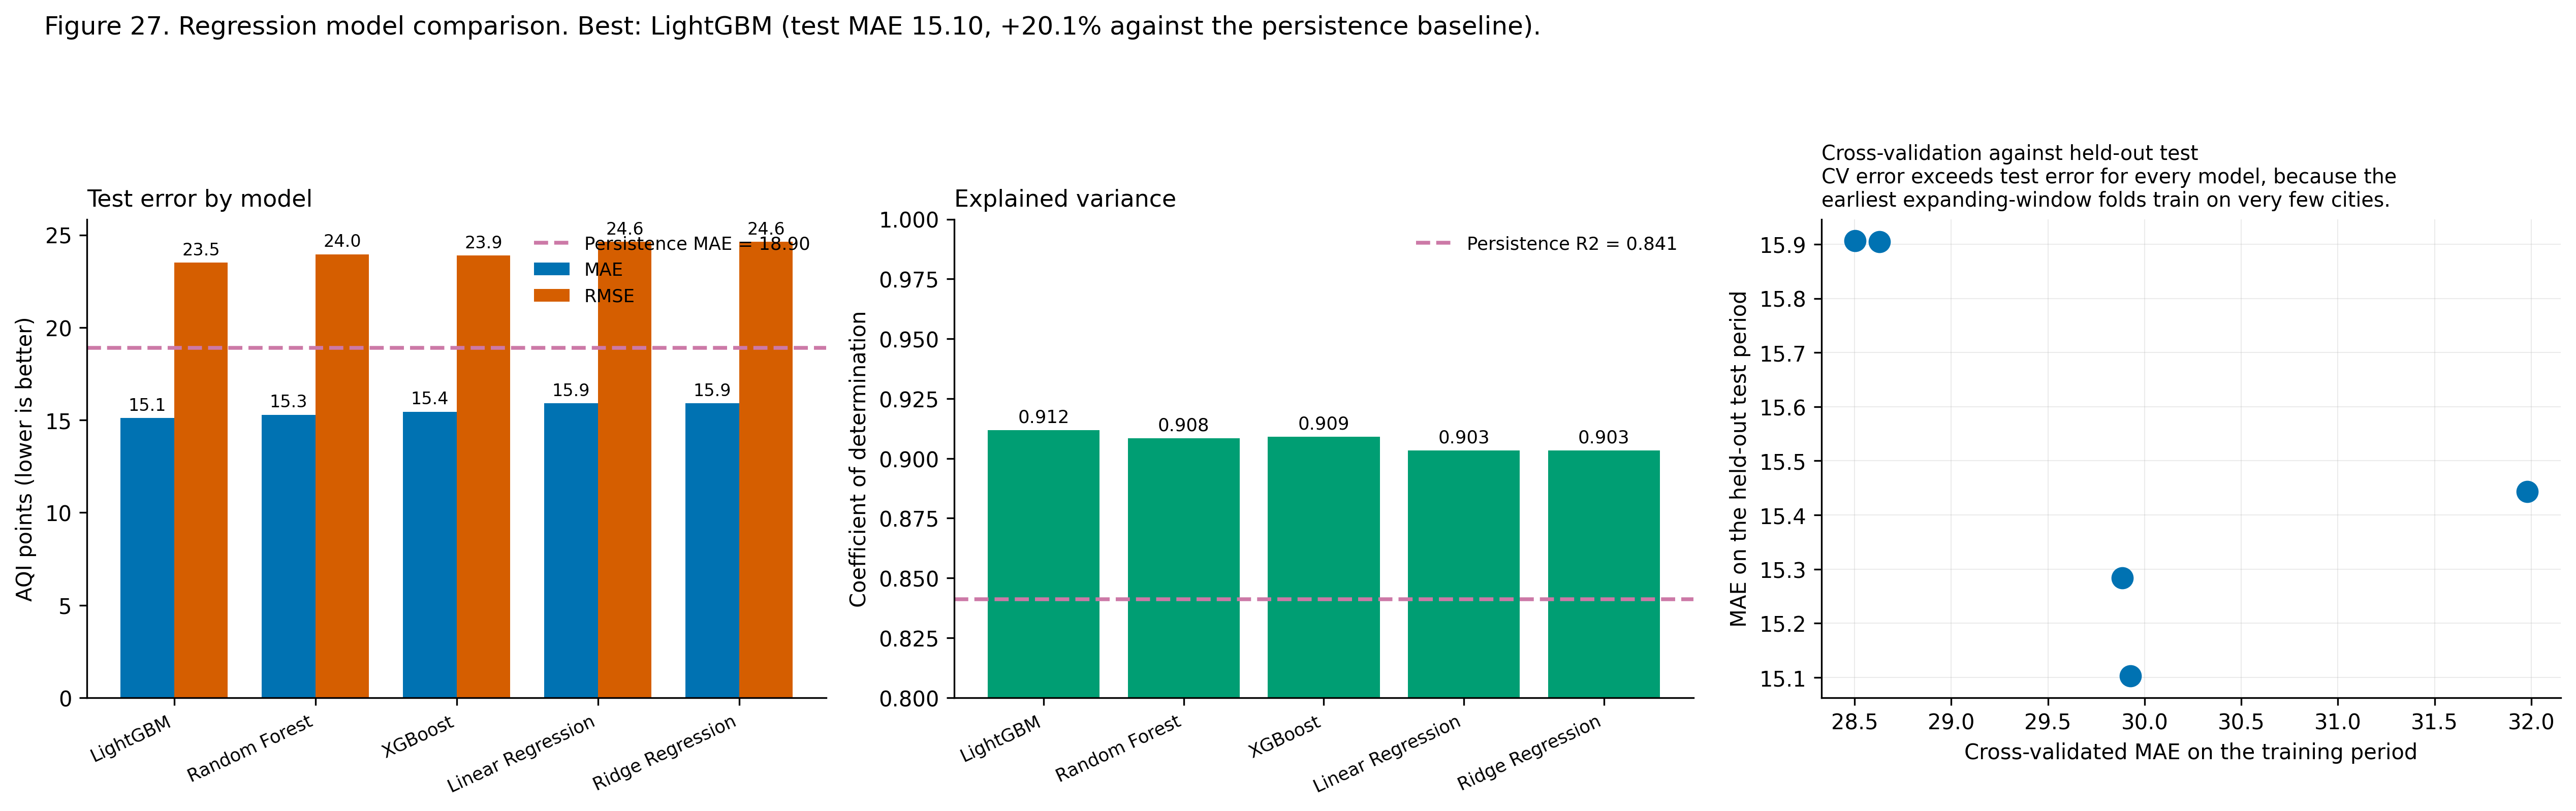

*Figure 1. Regression comparison against the persistence baseline.*

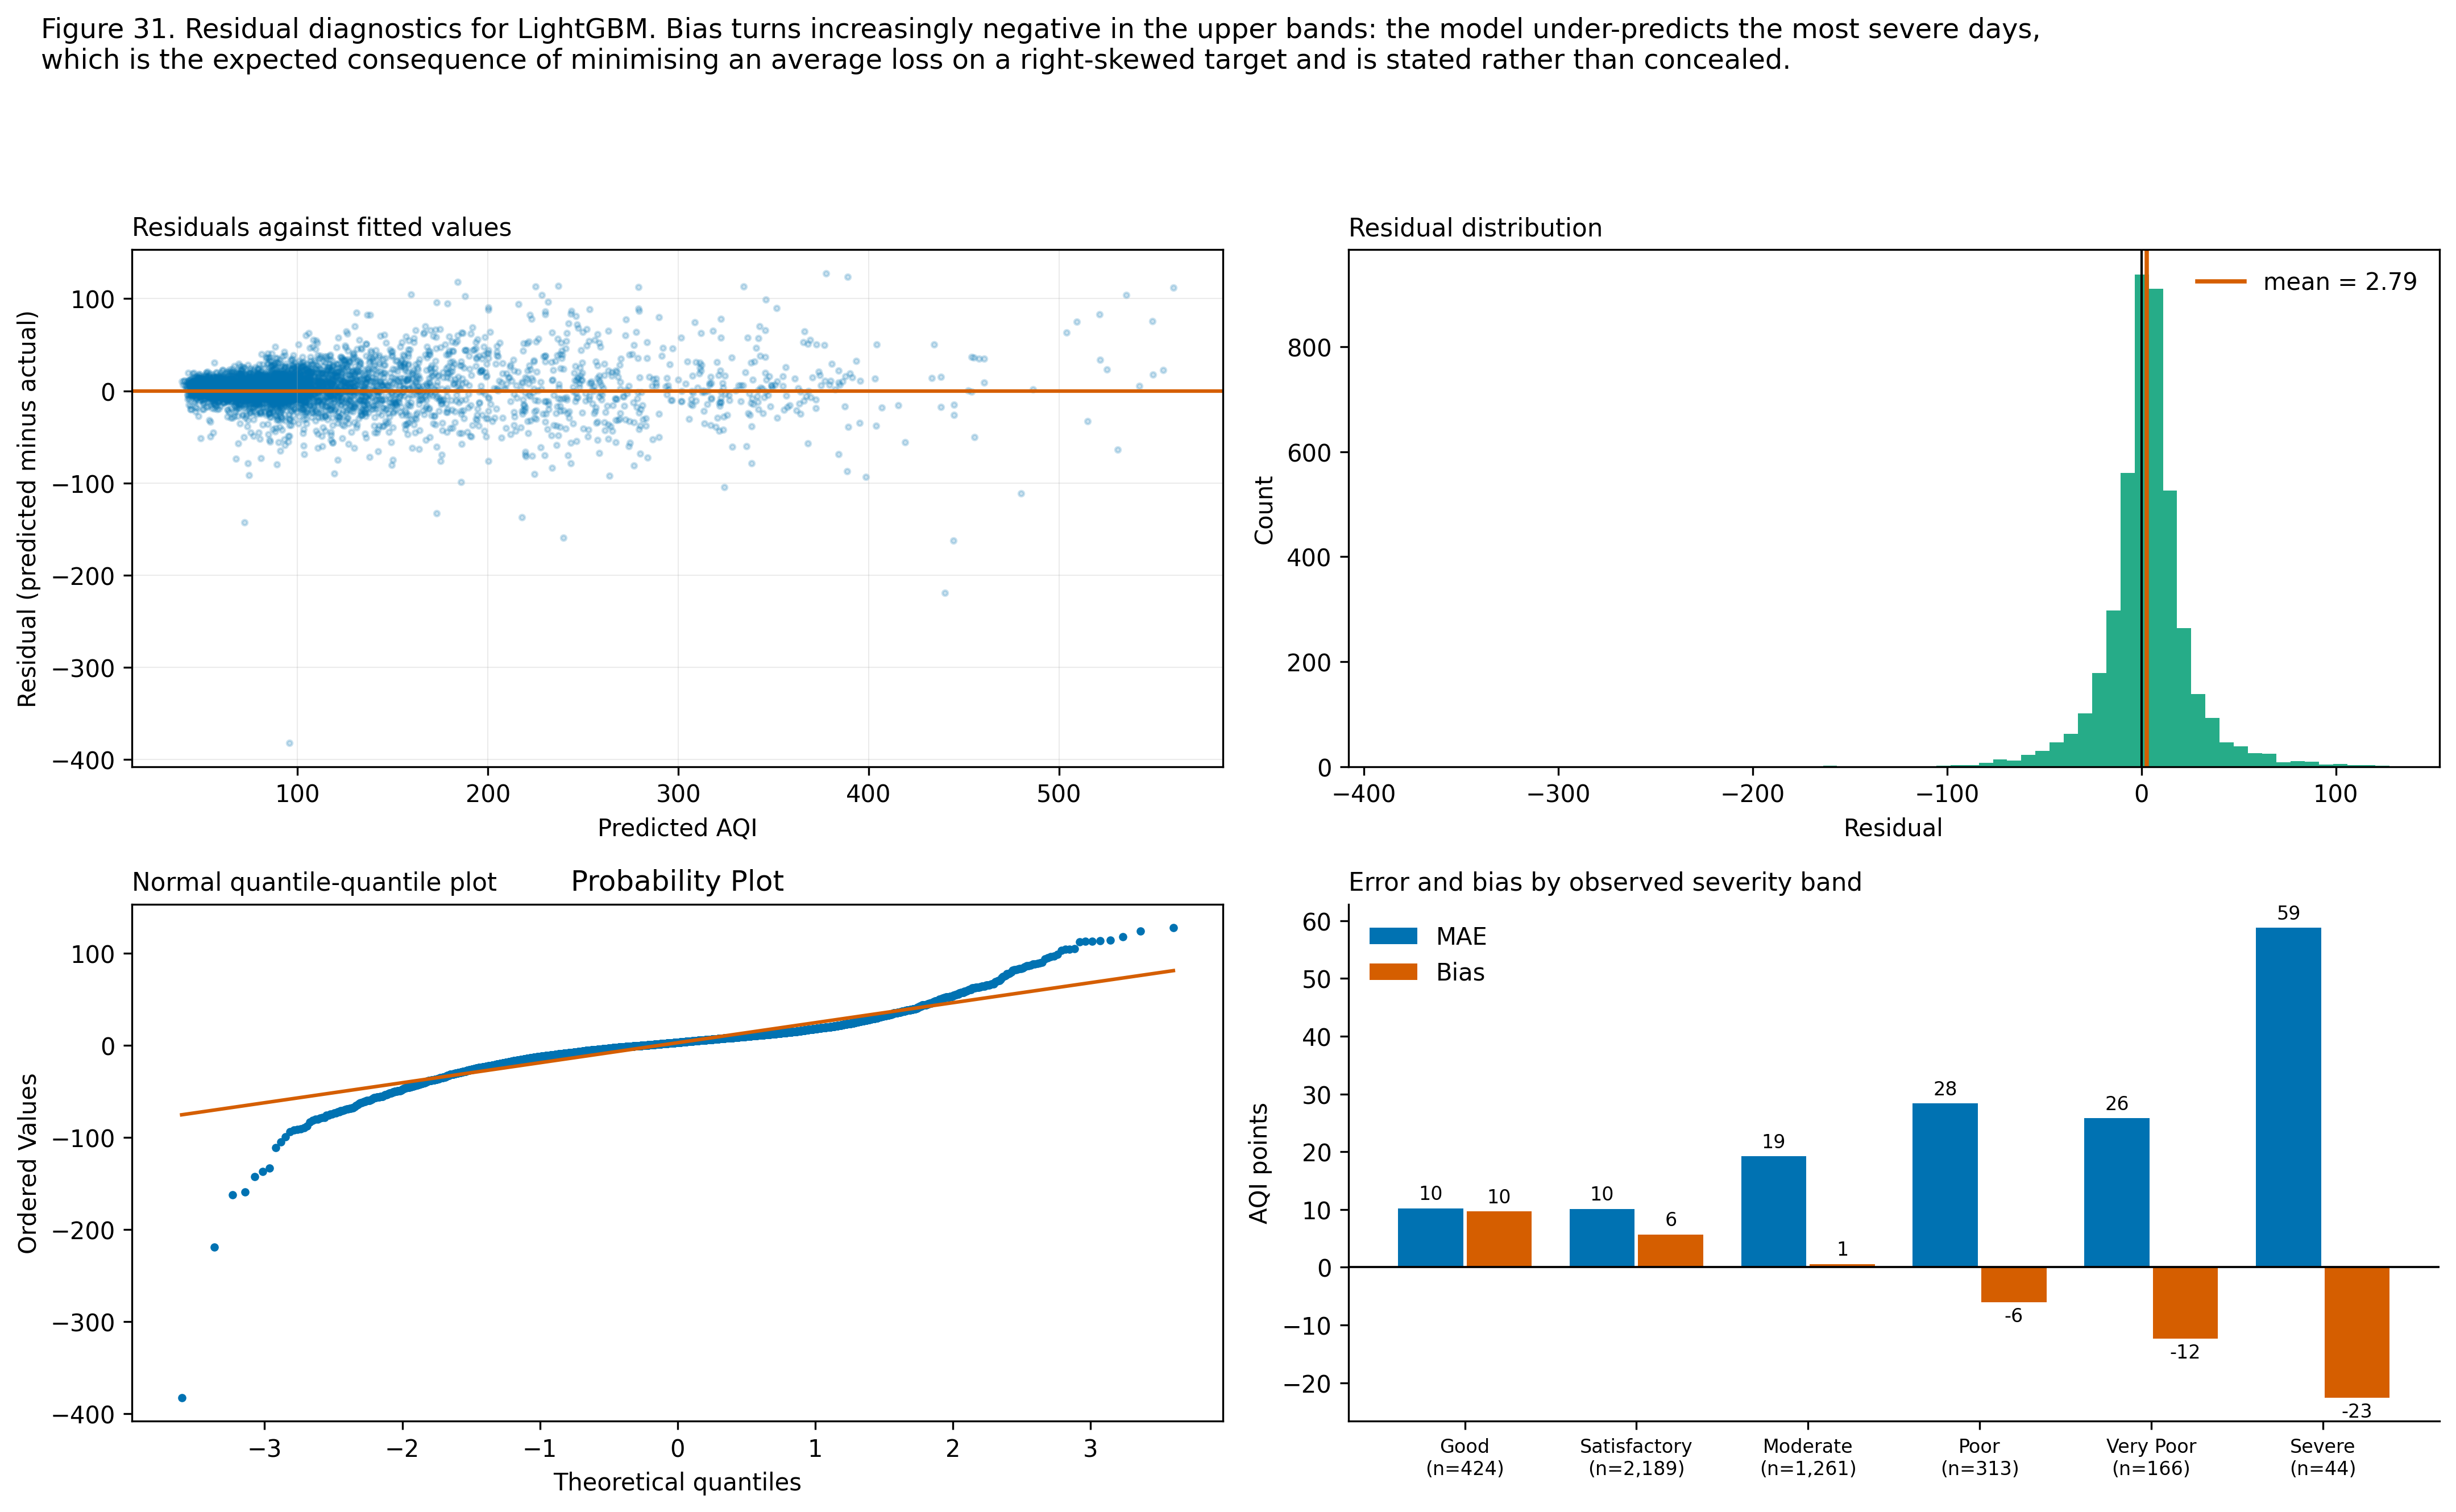

*Figure 2. Residual diagnostics for the selected regressor.*

> **Residual interpretation.** Residual bias turns negative in the upper bands, meaning the model under-predicts the most severe days. This is the expected consequence of fitting a squared or absolute loss on a right-skewed target: the optimiser buys accuracy on the many ordinary days at the cost of the few extreme ones. It is stated plainly because it is precisely the regime in which an advisory system must not be over-confident, and it is the reason the deployed application presents the predicted band with its classification confidence rather than the point estimate alone.

In [4]:
show("27_regression_comparison.png", "Figure 1. Regression comparison against the persistence baseline.")
show("31_residual_analysis.png", "Figure 2. Residual diagnostics for the selected regressor.")
display(Markdown(f"> **Residual interpretation.** {regression['residual_analysis']['interpretation']}"))

## 3. Classification: next-day band

Accuracy exceeds macro F1 for every model, and the gap is the cost of the rare classes. A reader shown only accuracy would conclude the models perform better than they do on exactly the bands that matter most for health protection.

In [5]:
display(Markdown(f"**Primary metric.** {classification['primary_metric_justification']}"))
display(pd.read_csv(RESULTS / "master_comparison_classification.csv"))

**Primary metric.** Macro-averaged F1 is the primary classification metric, declared before any model was fitted. The six CPCB buckets are imbalanced by a factor of 6.6 between the most and least frequent class, and the rarest classes are Good and Severe. Severe is the class on which the entire public-health purpose of the system rests: failing to warn on a Severe day is the costliest error the system can make, and it is also the error that overall accuracy is least sensitive to. Macro-F1 gives every class equal weight regardless of frequency, so a model cannot score well by ignoring the rare and dangerous classes. Accuracy, weighted F1, per-class F1, balanced accuracy, Cohen's kappa and one-versus-rest ROC-AUC are all reported alongside it, together with an ordinal error that measures how many severity bands a wrong prediction lands away from the truth.

,Model,Family,Imbalance strategy,CV macro F1,CV sd,Test macro F1,Test accuracy,Test weighted F1,Balanced accuracy,Cohen kappa,ROC-AUC (OvR),F1 Severe,F1 Good,Ordinal MAE,Within 1 band %,Train-test macro F1 gap,Fit seconds
0,XGBoost + SMOTE,gradient boosting,SMOTE oversampling inside each training fold,0.5709,0.1427,0.7411,0.7783,0.7794,0.7453,0.6648,0.9591,0.7595,0.6689,0.2238,99.82,0.2541,90.99
1,Random Forest + SMOTE,bagged trees,SMOTE oversampling inside each training fold,0.5599,0.1479,0.7390,0.7771,0.7759,0.7543,0.6575,0.9594,0.7789,0.6154,0.2256,99.77,0.2578,22.58
2,XGBoost,gradient boosting,none (compared against a SMOTE variant below),0.5545,0.1405,0.7342,0.7846,0.7809,0.7075,0.6643,0.9615,0.7532,0.6280,0.2179,99.77,0.2651,49.55
3,Logistic Regression,linear,class_weight='balanced',0.4414,0.1213,0.7236,0.7589,0.7586,0.7393,0.6328,0.9514,0.7191,0.6446,0.2449,99.66,-0.0538,1.85
4,Logistic Regression + SMOTE,linear,SMOTE oversampling inside each training fold,0.4402,0.1284,0.7197,0.7598,0.7593,0.7378,0.6331,0.9519,0.7234,0.6443,0.2440,99.66,-0.0438,4.89
5,Random Forest,bagged trees,class_weight='balanced_subsample',0.5472,0.1349,0.7184,0.7789,0.7695,0.7040,0.6504,0.9602,0.7765,0.4878,0.2229,99.86,0.2760,9.53
6,Persistence baseline (tomorrow = today),baseline,-,NaN,NaN,0.6803,0.7512,0.7511,0.6798,0.6193,NaN,0.6818,0.6833,0.2554,99.41,NaN,NaN
7,Decision Tree,tree,class_weight='balanced',0.5121,0.1229,0.6647,0.7118,0.7195,0.7330,0.5803,0.9212,0.6786,0.5897,0.2968,99.16,0.0510,2.02
8,SVM (RBF),kernel,class_weight='balanced',0.4593,0.1615,0.6359,0.7196,0.7244,0.6487,0.5862,NaN,0.4658,0.6142,0.2888,99.27,0.2740,10.45
9,KNN (k=15),instance-based,distance weighting (no class weighting available),0.4327,0.0678,0.5635,0.6848,0.6602,0.5421,0.4960,0.9052,0.6197,0.1681,0.3241,99.14,0.4365,0.07


In [6]:
display(Markdown("### Class weighting against SMOTE, head to head"))
display(pd.DataFrame(classification["smote_head_to_head"]))
display(Markdown("### Per-class performance of the selected classifier"))
display(pd.DataFrame(classification["best_test_metrics"]["per_class"]))

### Class weighting against SMOTE, head to head

,pair,baseline_strategy,macro_f1_weighted_or_plain,macro_f1_smote,delta_macro_f1,severe_f1_weighted_or_plain,severe_f1_smote,winner
0,Random Forest vs Random Forest + SMOTE,class_weight='balanced_subsample',0.7184,0.7390,0.0206,0.7765,0.7789,Random Forest + SMOTE
1,XGBoost vs XGBoost + SMOTE,none (compared against a SMOTE variant below),0.7342,0.7411,0.0069,0.7532,0.7595,XGBoost + SMOTE
2,Logistic Regression vs Logistic Regression + S...,class_weight='balanced',0.7236,0.7197,-0.0039,0.7191,0.7234,Logistic Regression


### Per-class performance of the selected classifier

,class,precision,recall,f1,support
0,Good,0.6421,0.6981,0.6689,424
1,Satisfactory,0.8432,0.8104,0.8265,2189
2,Moderate,0.7608,0.7692,0.7650,1261
3,Poor,0.6656,0.6869,0.6761,313
4,Very Poor,0.6884,0.8253,0.7507,166
5,Severe,0.8571,0.6818,0.7595,44


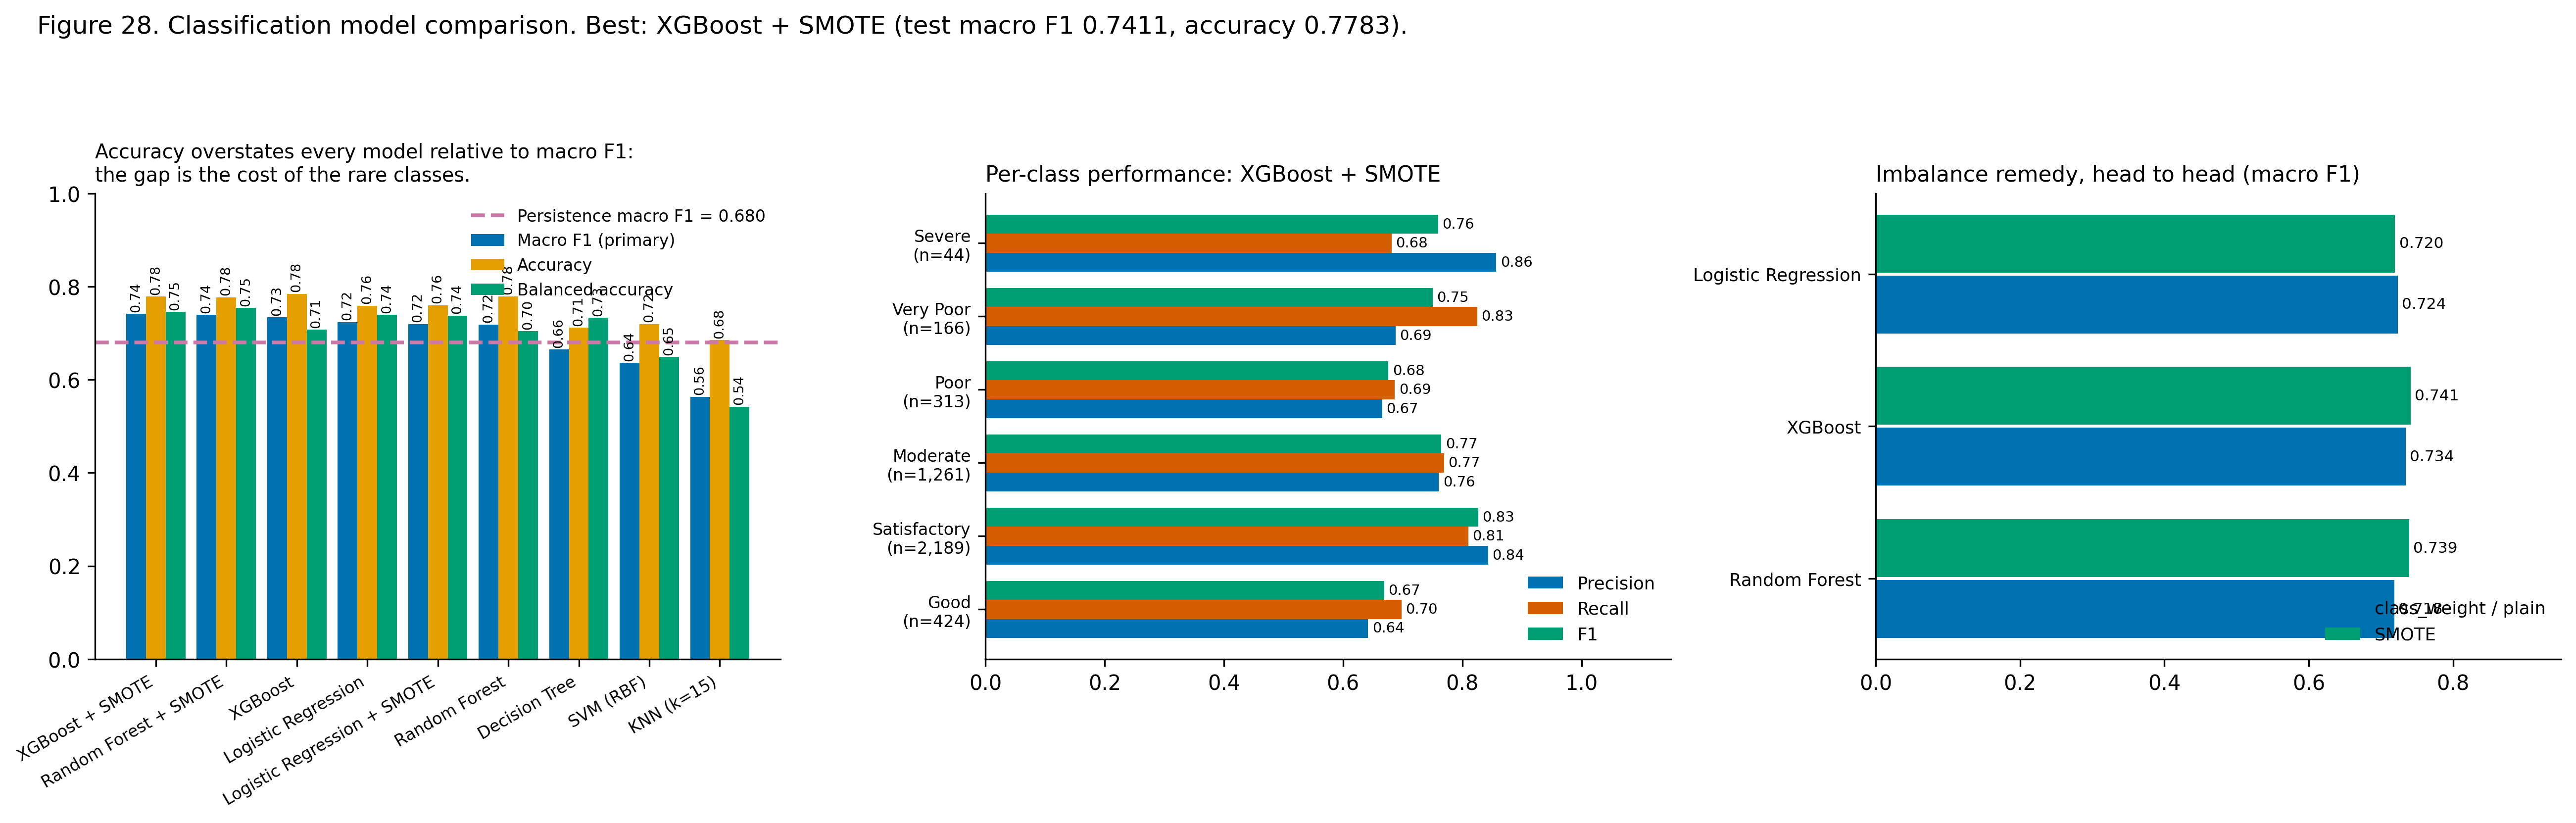

*Figure 3. Classification comparison and per-class performance.*

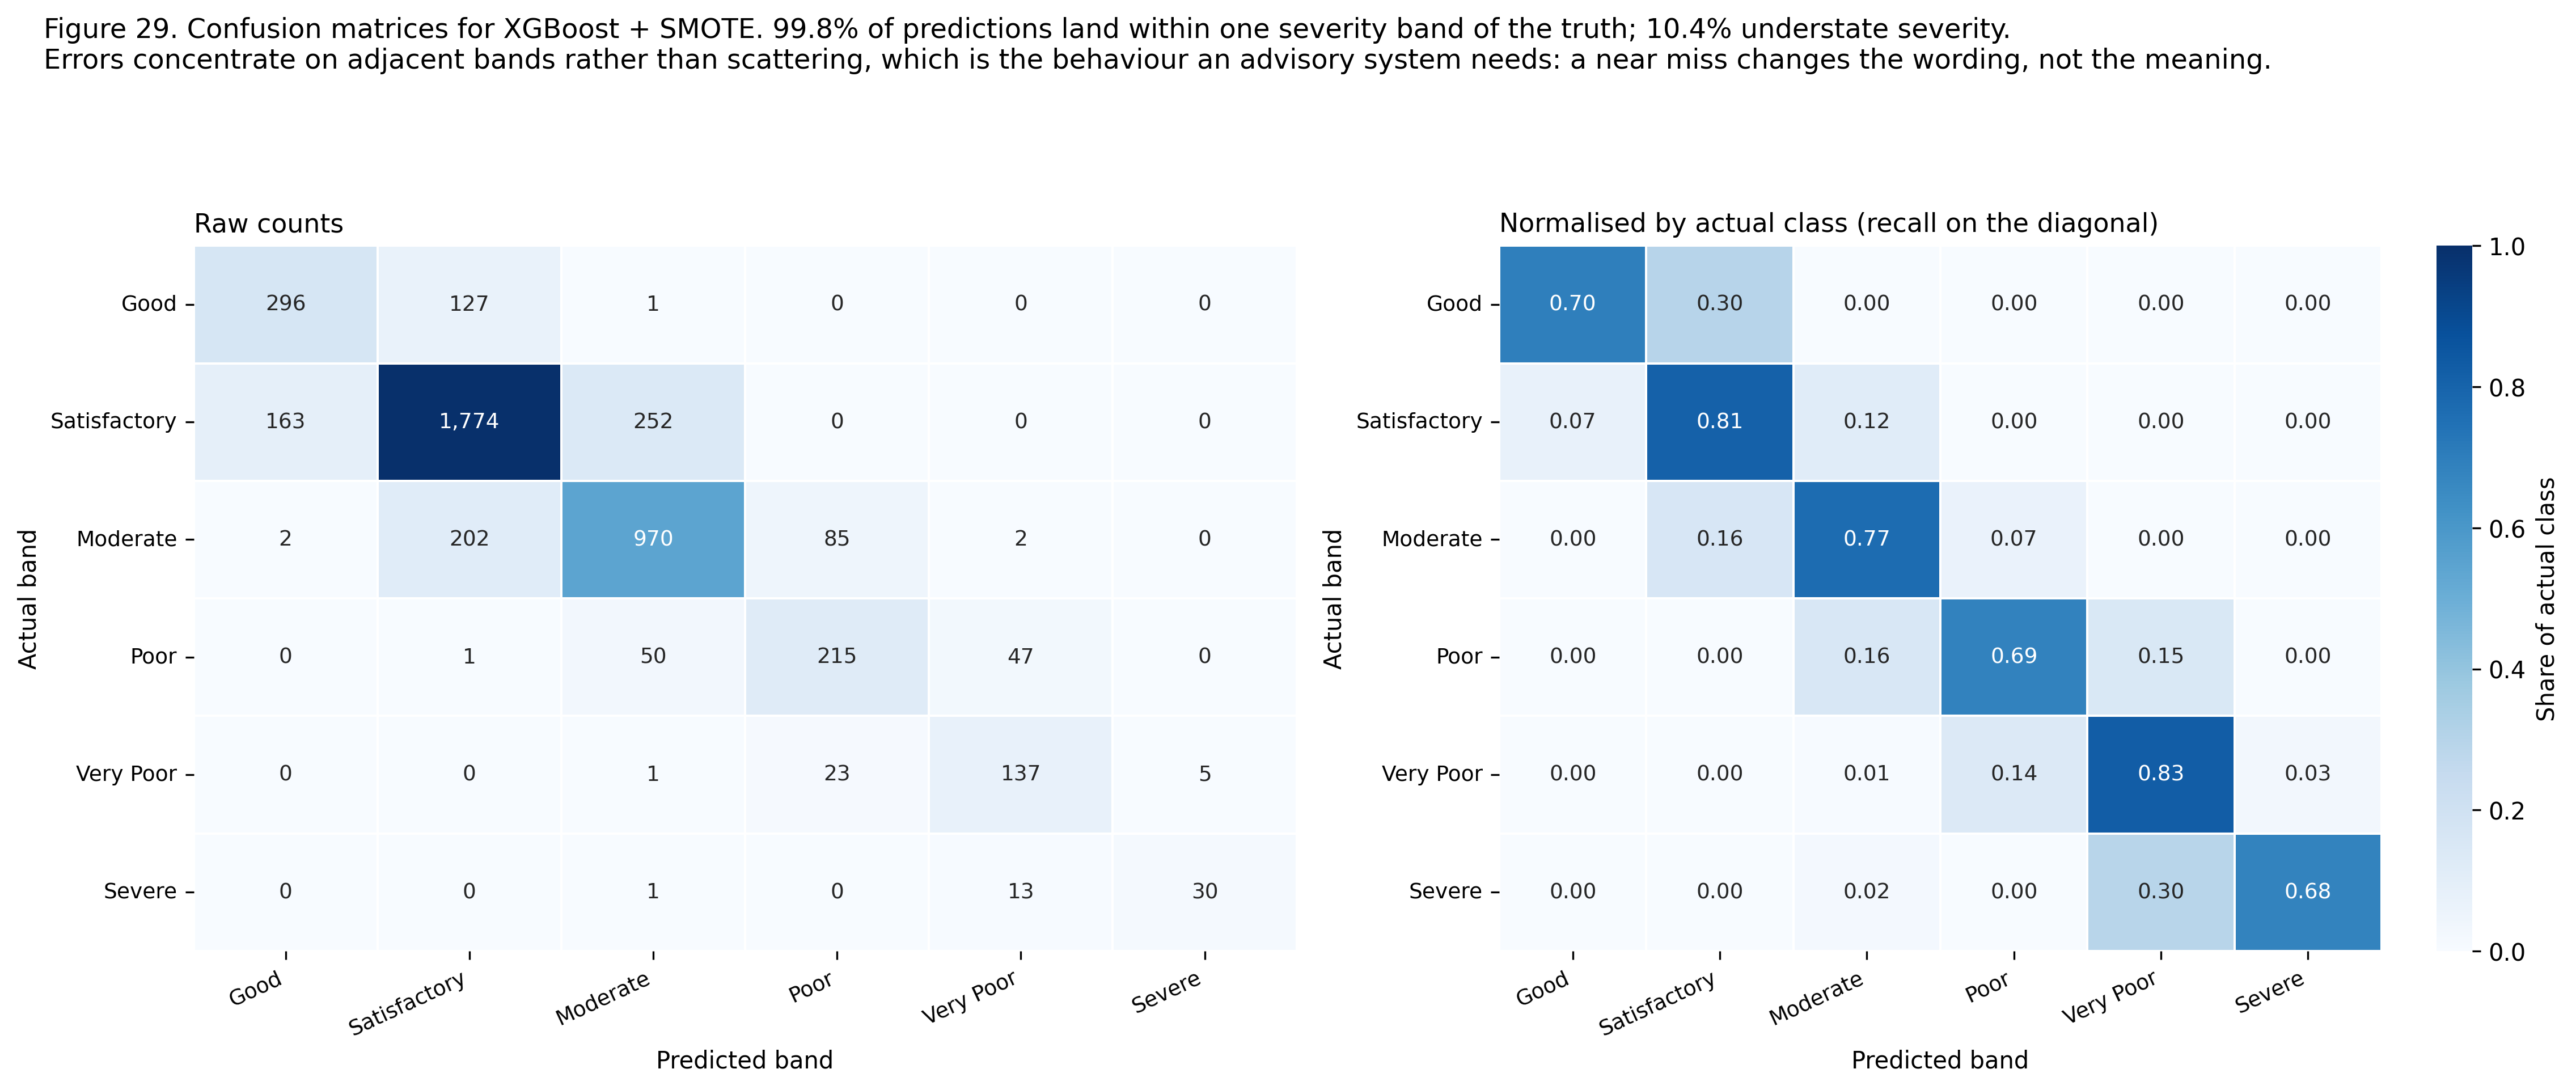

*Figure 4. Confusion matrices, raw and normalised.*

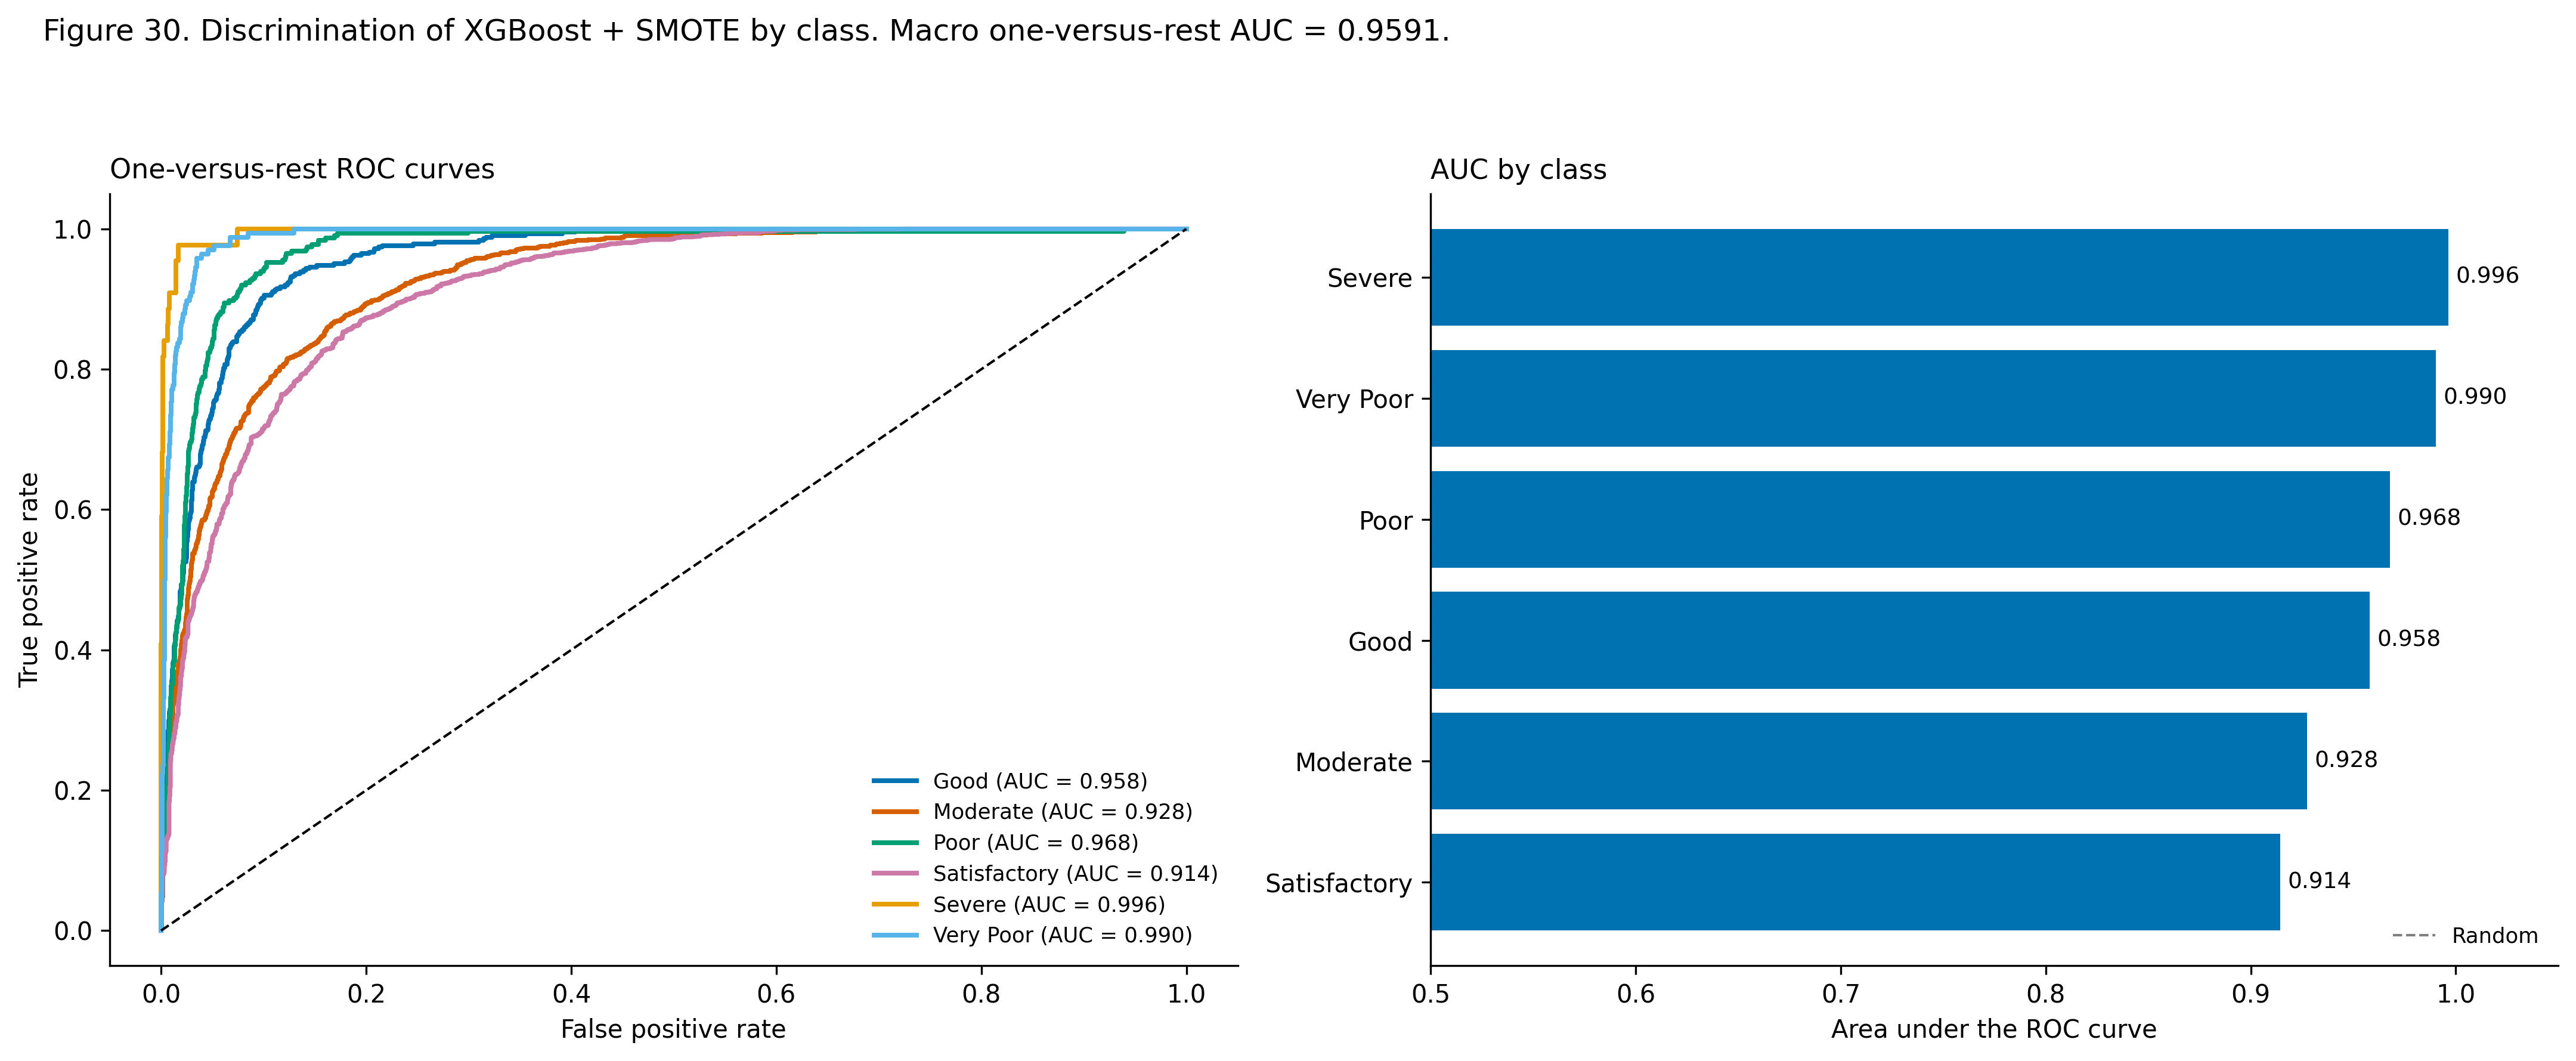

*Figure 5. One-versus-rest ROC curves.*

In [7]:
show("28_classification_comparison.png", "Figure 3. Classification comparison and per-class performance.")
show("29_confusion_matrices.png", "Figure 4. Confusion matrices, raw and normalised.")
show("30_roc_curves.png", "Figure 5. One-versus-rest ROC curves.")

### The error that actually matters

Overall accuracy treats every mistake alike. For a health advisory they are not alike: predicting one band too clean is a wording problem, and predicting three bands too clean is a safety problem.

| Statistic | Value |
| --- | --- |
| Test predictions | 4,397 |
| Wrong | 975 (22.17%) |
| Wrong by 2+ bands | 8 (0.182%) |
| **Understating severity by 2+ bands** | **5 (0.114%)** |

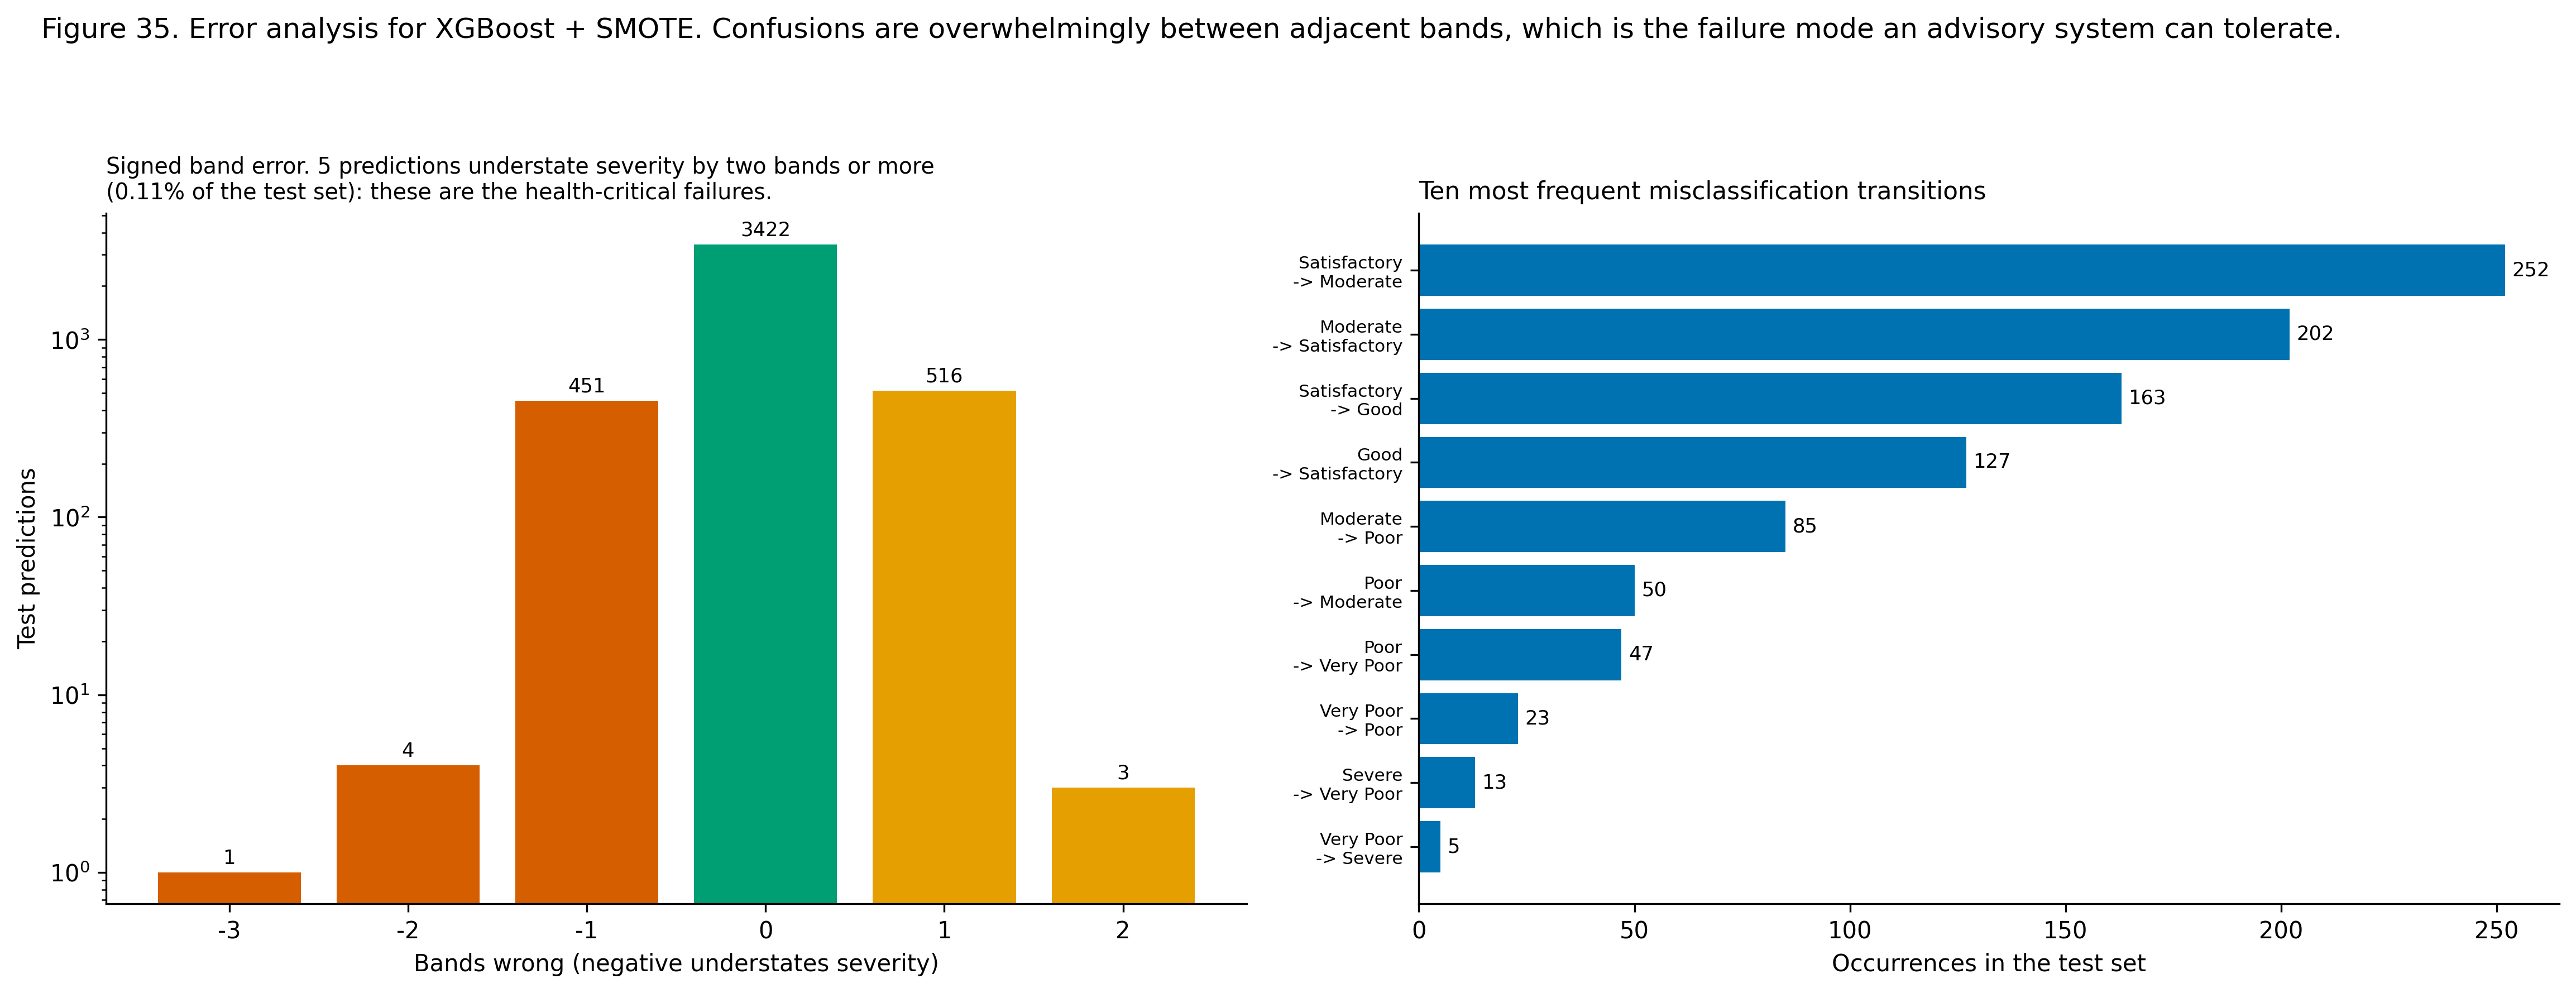

*Figure 6. Signed band error and the most frequent transitions.*

> The signed error distribution is sharply peaked at zero and decays fast, and almost all remaining error is a single band in either direction. The subset that matters operationally is the tail that understates severity by two bands or more, because that is the case in which a reader is told the air is acceptable when it is not. Its size is reported above as an explicit safety statistic rather than being left implicit inside the macro-F1.

In [8]:
errors = load("error_analysis.json")
display(Markdown(
    f"| Statistic | Value |\n| --- | --- |\n"
    f"| Test predictions | {errors['n_test']:,} |\n"
    f"| Wrong | {errors['n_wrong']:,} ({errors['error_rate_pct']}%) |\n"
    f"| Wrong by 2+ bands | {errors['n_wrong_by_two_or_more_bands']:,} "
    f"({errors['pct_wrong_by_two_or_more_bands']}%) |\n"
    f"| **Understating severity by 2+ bands** | "
    f"**{errors['n_understating_severity_by_two_or_more']:,} "
    f"({errors['pct_understating_severity_by_two_or_more']}%)** |"
))
show("35_error_analysis.png", "Figure 6. Signed band error and the most frequent transitions.")
display(Markdown(f"> {errors['interpretation']}"))

## 4. Clustering: city archetypes

Two cities can share a mean AQI and still need opposite interventions. Clustering on the *composition* of the pollutant mix rather than its magnitude separates kinds of problem from degrees of severity.

In [9]:
clustering = load("evaluation_clustering.json")
display(pd.DataFrame(clustering["k_selection"]["candidates"]))
display(Markdown(f"**Selection rule.** {clustering['k_selection']['selection_rule']}"))
display(Markdown(f"*{clustering['k_selection']['power_caveat']}*"))
display(Markdown(f"**Algorithm agreement.** {clustering['algorithm_agreement']['interpretation']}"))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,cluster_sizes
0,2,41.6903,0.3553,1.0464,7.2702,"[9, 3]"
1,3,30.2244,0.2259,1.0703,6.2198,"[4, 5, 3]"
2,4,19.4887,0.2418,0.8596,7.1852,"[1, 5, 4, 2]"
3,5,15.0559,0.1780,0.8999,6.6188,"[3, 3, 1, 2, 3]"


**Selection rule.** The rule was fixed before the indices were inspected. Any k whose partition contains a singleton cluster is discarded, because a cluster of one city cannot support a generalisable archetype claim; among the remaining candidates the highest silhouette coefficient decides. Silhouette is the decisive index because it measures separation relative to cohesion and is comparable across k, whereas inertia falls monotonically with k by construction and cannot select k on its own. The four indices do not agree here, and the full vote tally is reported rather than only the winner.

*Twelve cities is a small sample for a clustering problem. Silhouette coefficients in the 0.2 to 0.4 range indicate real but moderate separation, and the partition should be read as an interpretive organising device for policy discussion rather than as a claim of sharply bounded natural classes. Every candidate partition is reported below with its scores so that this is visible rather than implied.*

**Algorithm agreement.** An adjusted Rand index of 1.000 between K-Means and Ward agglomerative clustering indicates that the partition is reproduced almost exactly by an algorithm with a different objective, which is evidence that it reflects structure in the data rather than an artefact of the method.

,cluster,archetype,defining_pollutant,n_cities,cities,policy_lever
0,0,"Lower-burden, vehicular NOx led",NO2,9,"[Amaravati, Amritsar, Bengaluru, Chennai, Hyde...","Oxidised nitrogen leads the mix, which is the ..."
1,1,"High-burden, fine-particulate led",PM2.5,3,"[Delhi, Gurugram, Lucknow]","Fine particulate leads the mix, which points t..."


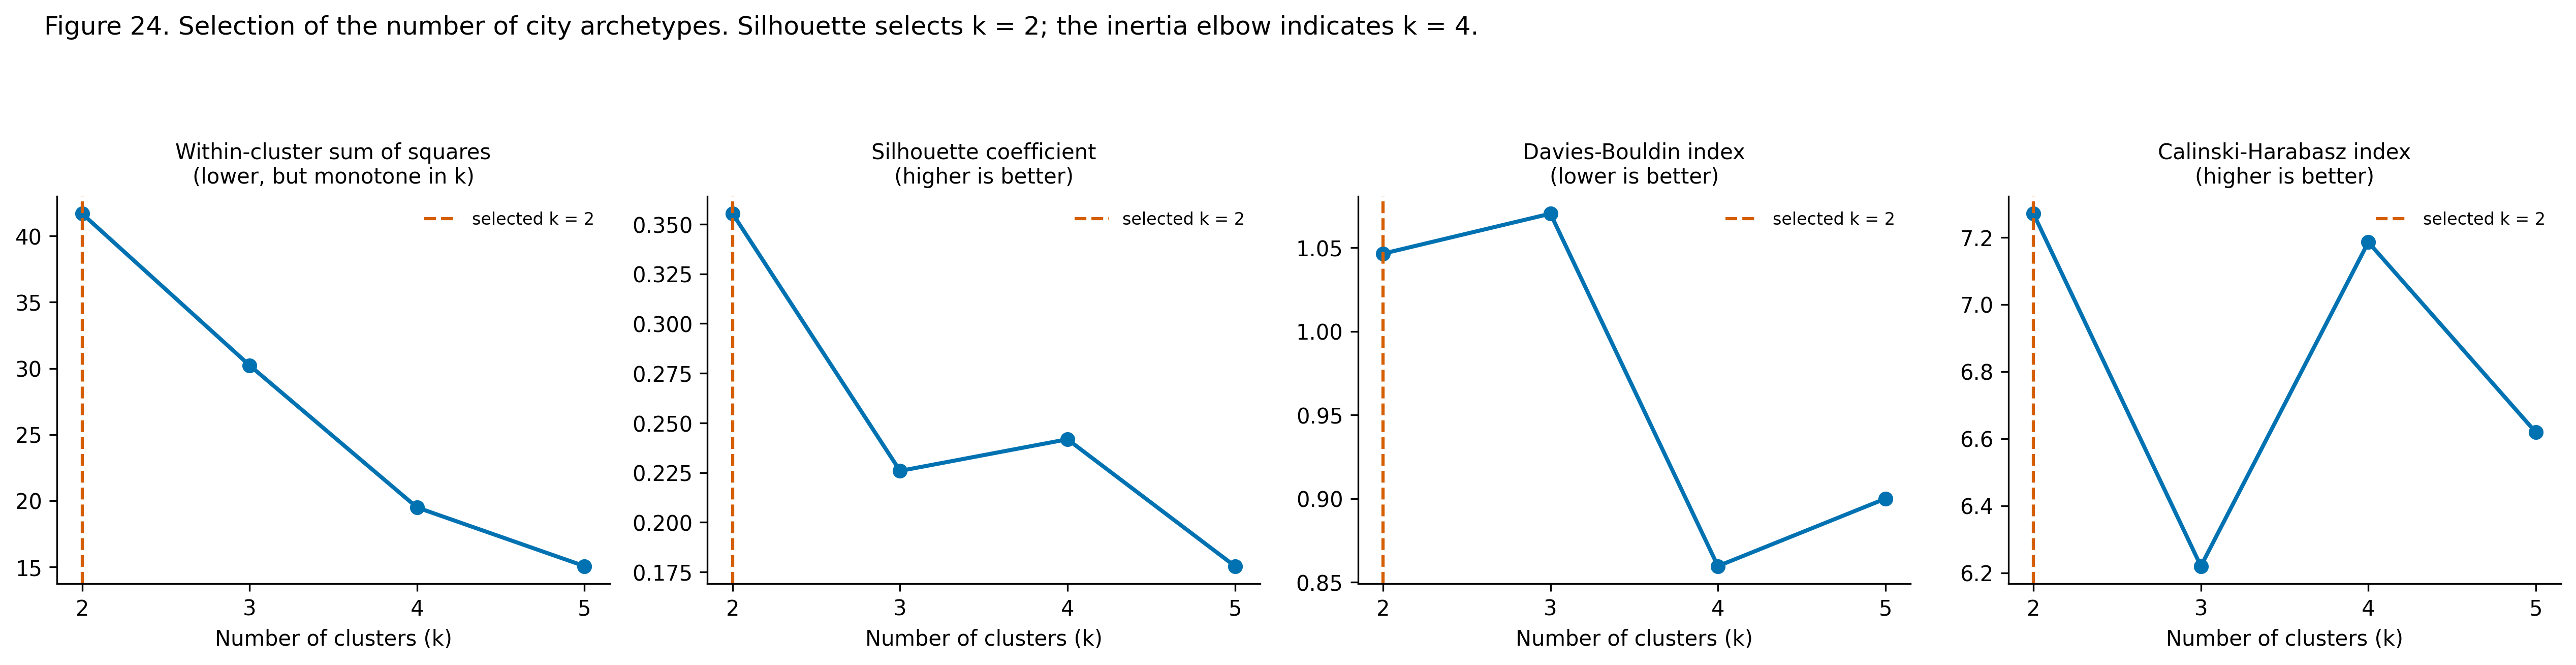

*Figure 7. Selection of the number of archetypes.*

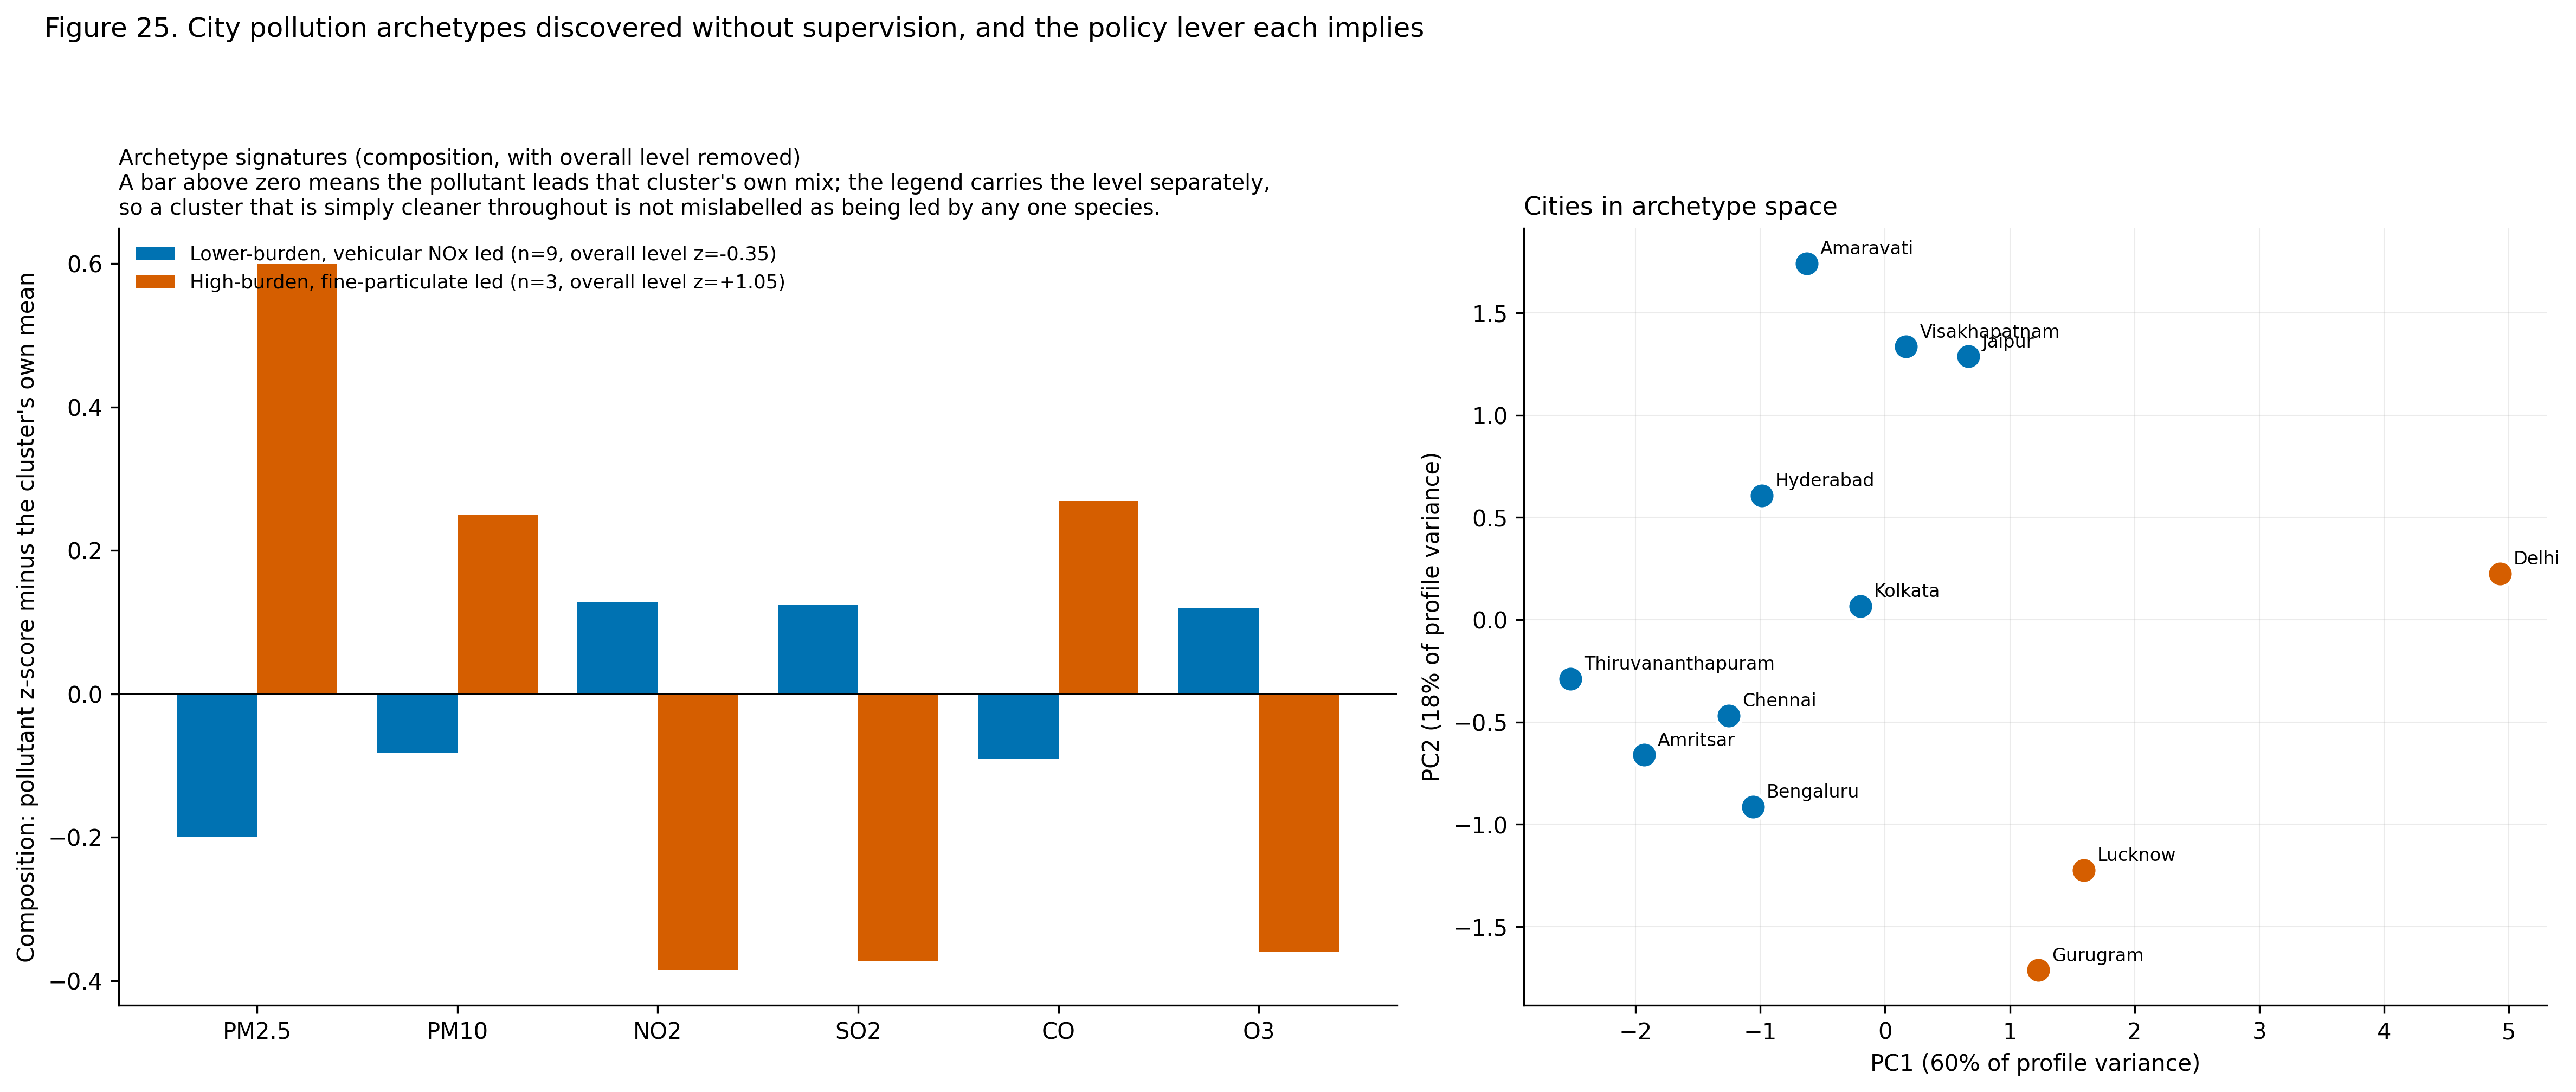

*Figure 8. Archetype signatures and the cities in archetype space.*

In [10]:
display(pd.DataFrame(clustering["archetypes"])[[
    "cluster", "archetype", "defining_pollutant", "n_cities", "cities", "policy_lever",
]])
show("24_clustering_selection.png", "Figure 7. Selection of the number of archetypes.")
show("25_cluster_profiles.png", "Figure 8. Archetype signatures and the cities in archetype space.")

## 5. Hyperparameter optimisation, and what it was worth

**Strategy.** RandomizedSearchCV over large spaces, GridSearchCV over the one-dimensional Ridge penalty. Every search uses TimeSeriesSplit, so each validation fold lies strictly after its training folds.

### Regression: LightGBM

,Setting,MAE,RMSE,R2,MAPE_pct,MAPE_n_used,median_absolute_error,bias,n
0,Default,15.1028,23.4986,0.9119,14.5791,4397,9.7133,2.7921,4397
1,Tuned,15.0488,23.4130,0.9125,14.4445,4397,9.4987,2.6877,4397


Best parameters: `{'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0.5, 'num_leaves': 95, 'n_estimators': 400, 'min_child_samples': 60, 'max_depth': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.5}`

### Classification: XGBoost

,Setting,macro_f1,accuracy,weighted_f1,balanced_accuracy
0,Default,0.7342,0.7846,0.7809,0.7075
1,Tuned,0.7452,0.7933,0.7911,0.7327


Best parameters: `{'estimator__subsample': 0.6, 'estimator__reg_lambda': 1.0, 'estimator__n_estimators': 600, 'estimator__min_child_weight': 10, 'estimator__max_depth': 10, 'estimator__learning_rate': 0.01, 'estimator__gamma': 1.0, 'estimator__colsample_bytree': 0.7}`

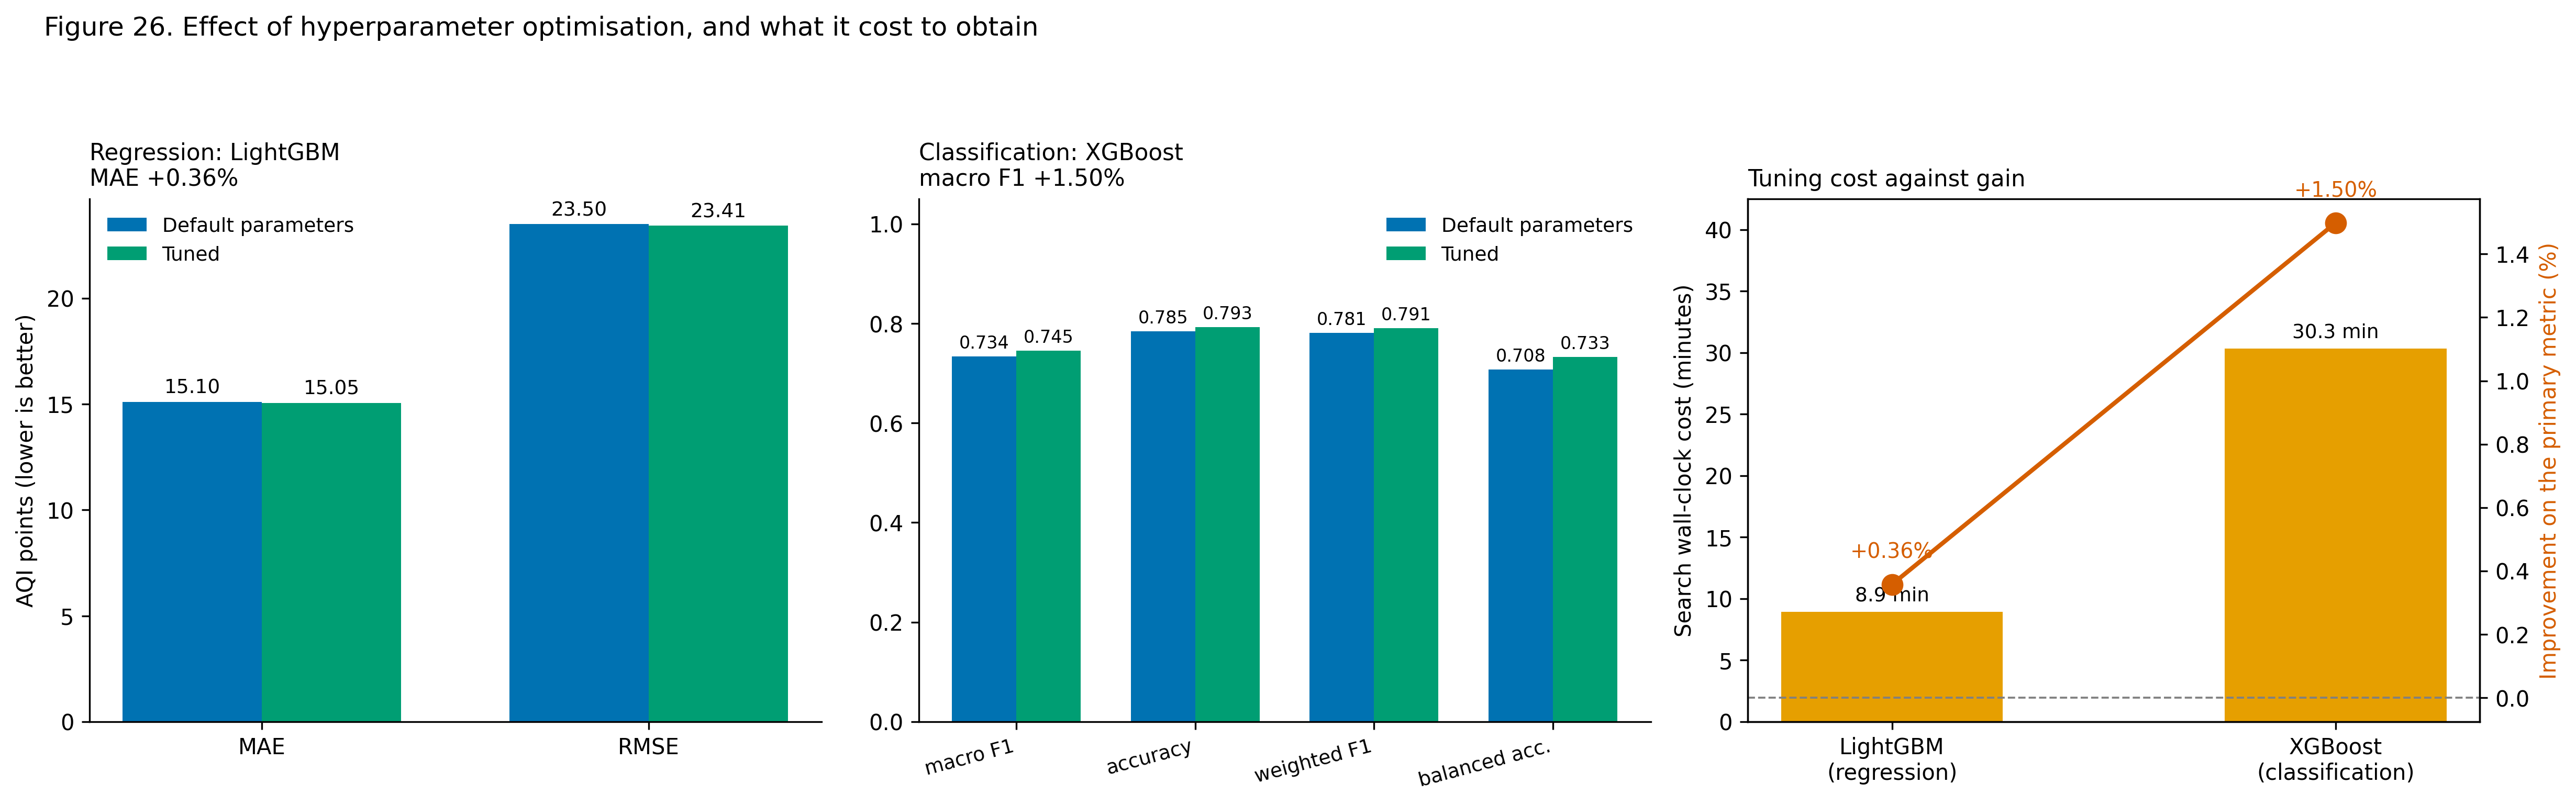

*Figure 9. Effect of tuning, and what it cost.*

> **Cost against gain.** The two randomised searches together consumed 39.3 minutes of wall-clock time and 322 model fits, and moved the primary metrics by +0.36% (regression MAE) and +1.50% (classification macro-F1). The gains are real but modest relative to the gains from feature engineering, which moved regression MAE from the persistence baseline by a far larger margin. The honest reading is that on this problem the representation matters more than the hyperparameters, and that a practitioner with limited time should spend it on features first.

In [11]:
tuning = load("tuning_report.json")
display(Markdown(f"**Strategy.** {tuning['strategy']}"))
for task in ("regression", "classification"):
    entry = tuning[task]
    display(Markdown(f"### {task.capitalize()}: {entry['model']}"))
    display(pd.DataFrame([
        {"Setting": "Default", **entry["untuned_test"]},
        {"Setting": "Tuned", **entry["tuned_test"]},
    ]))
    display(Markdown(f"Best parameters: `{entry['best_params']}`"))
show("26_tuning_before_after.png", "Figure 9. Effect of tuning, and what it cost.")
display(Markdown(f"> **Cost against gain.** {tuning['cost_vs_gain']['assessment']}"))

## 6. Explainability

A health advisory that cannot say *why* it is warning is hard to act on and hard to trust.

**Method.** TreeSHAP exact Shapley values. Shapley attribution is used because it is the only additive feature attribution satisfying efficiency: for any single prediction the contributions sum exactly to the difference between that prediction and the model's base value, so a local explanation is complete rather than merely indicative.

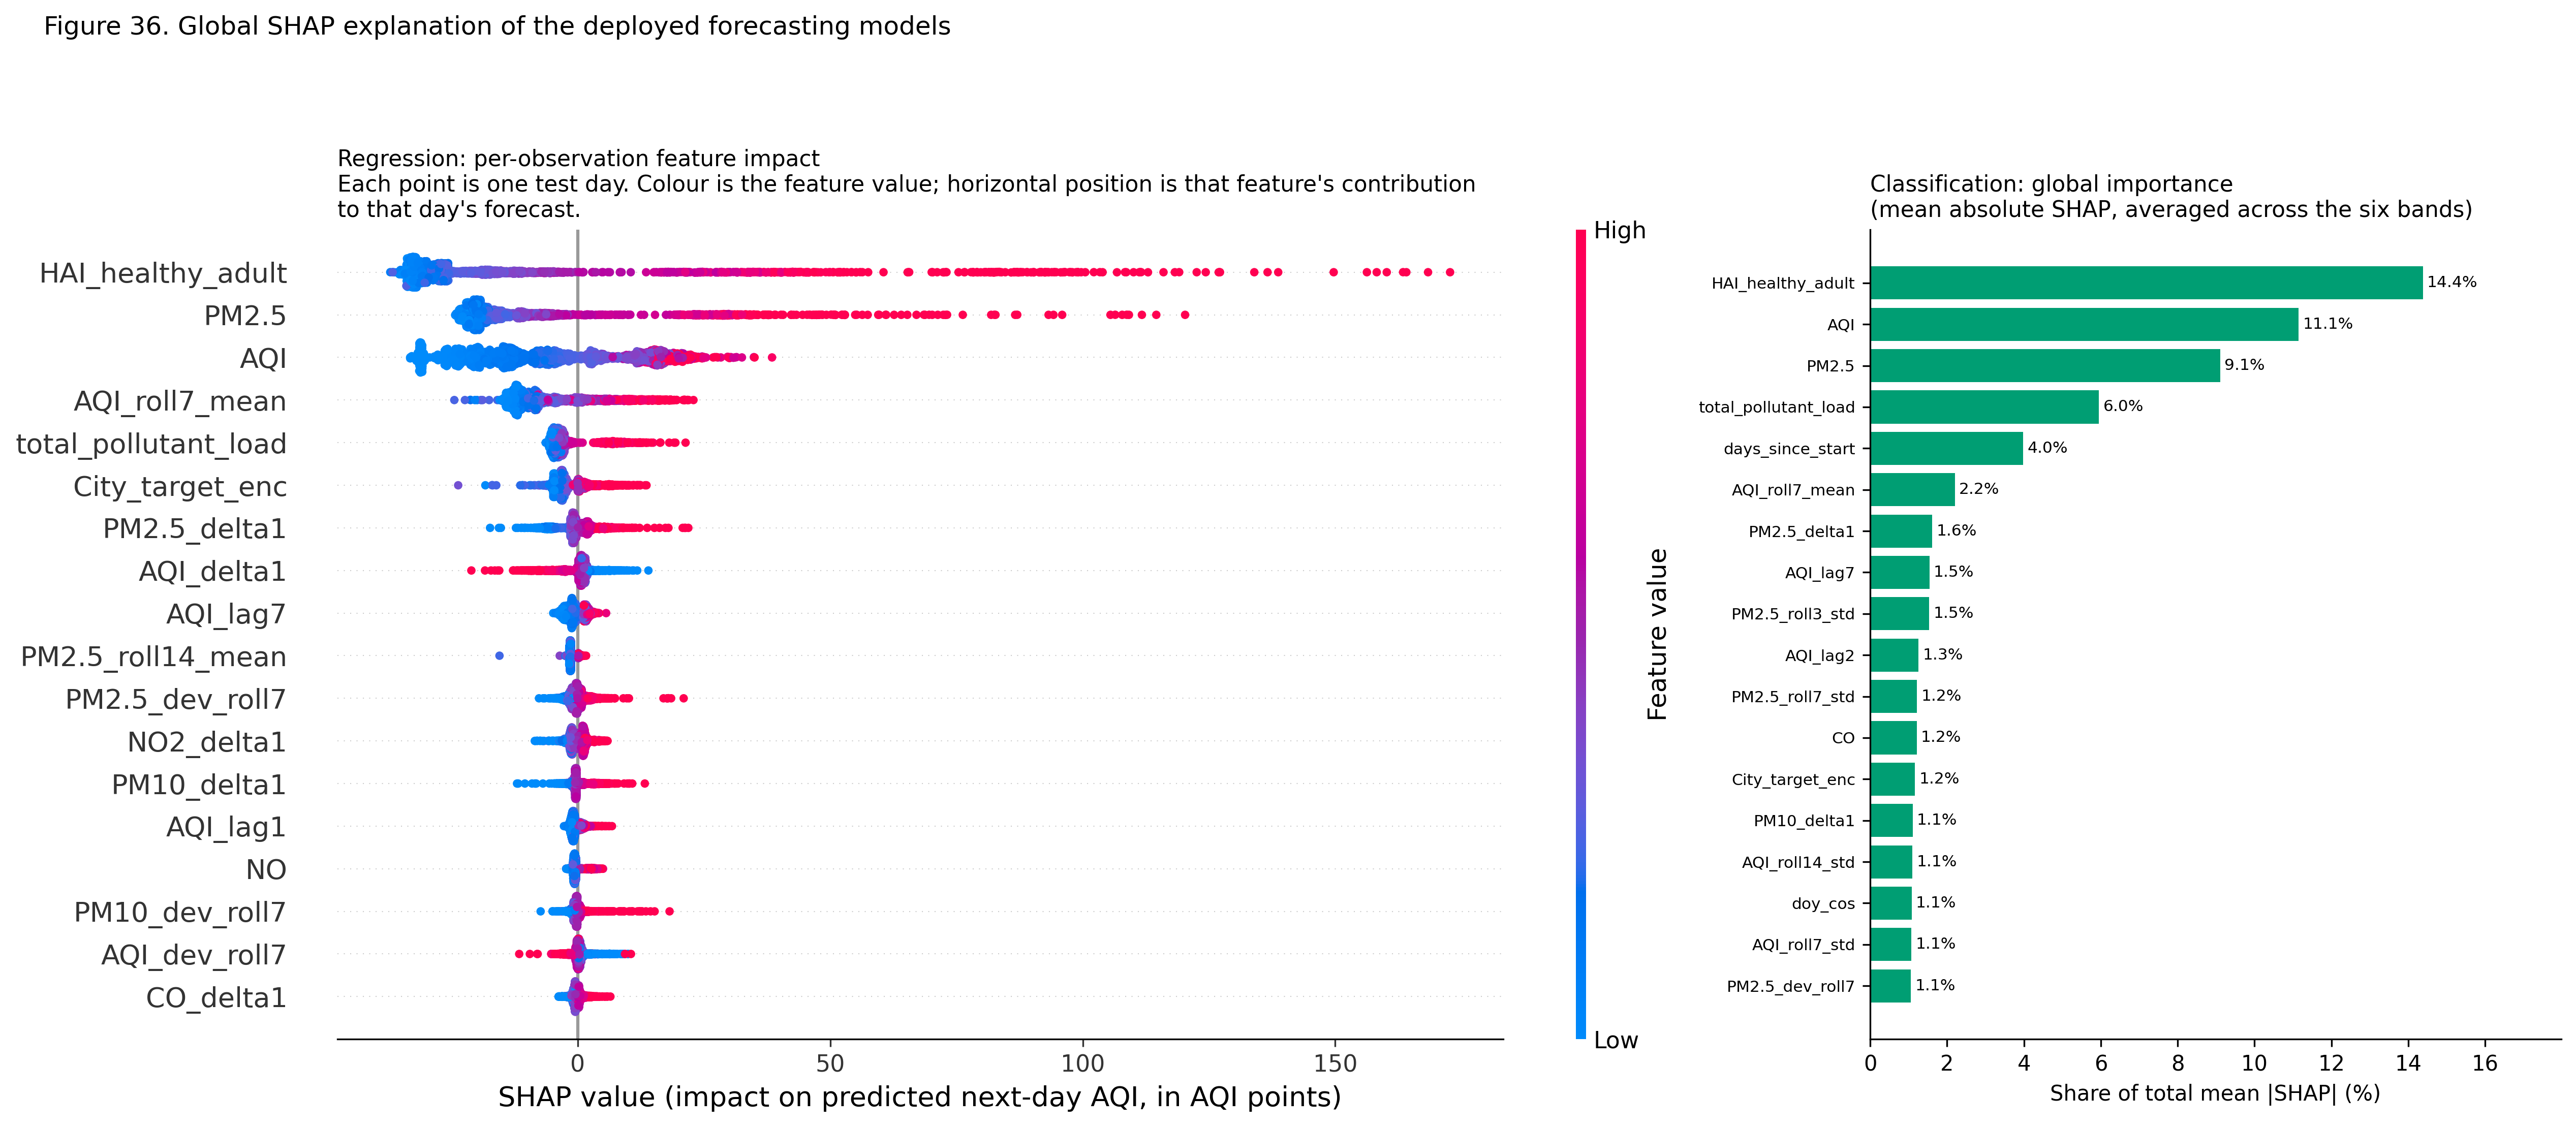

*Figure 10. Global SHAP explanation of both deployed models.*

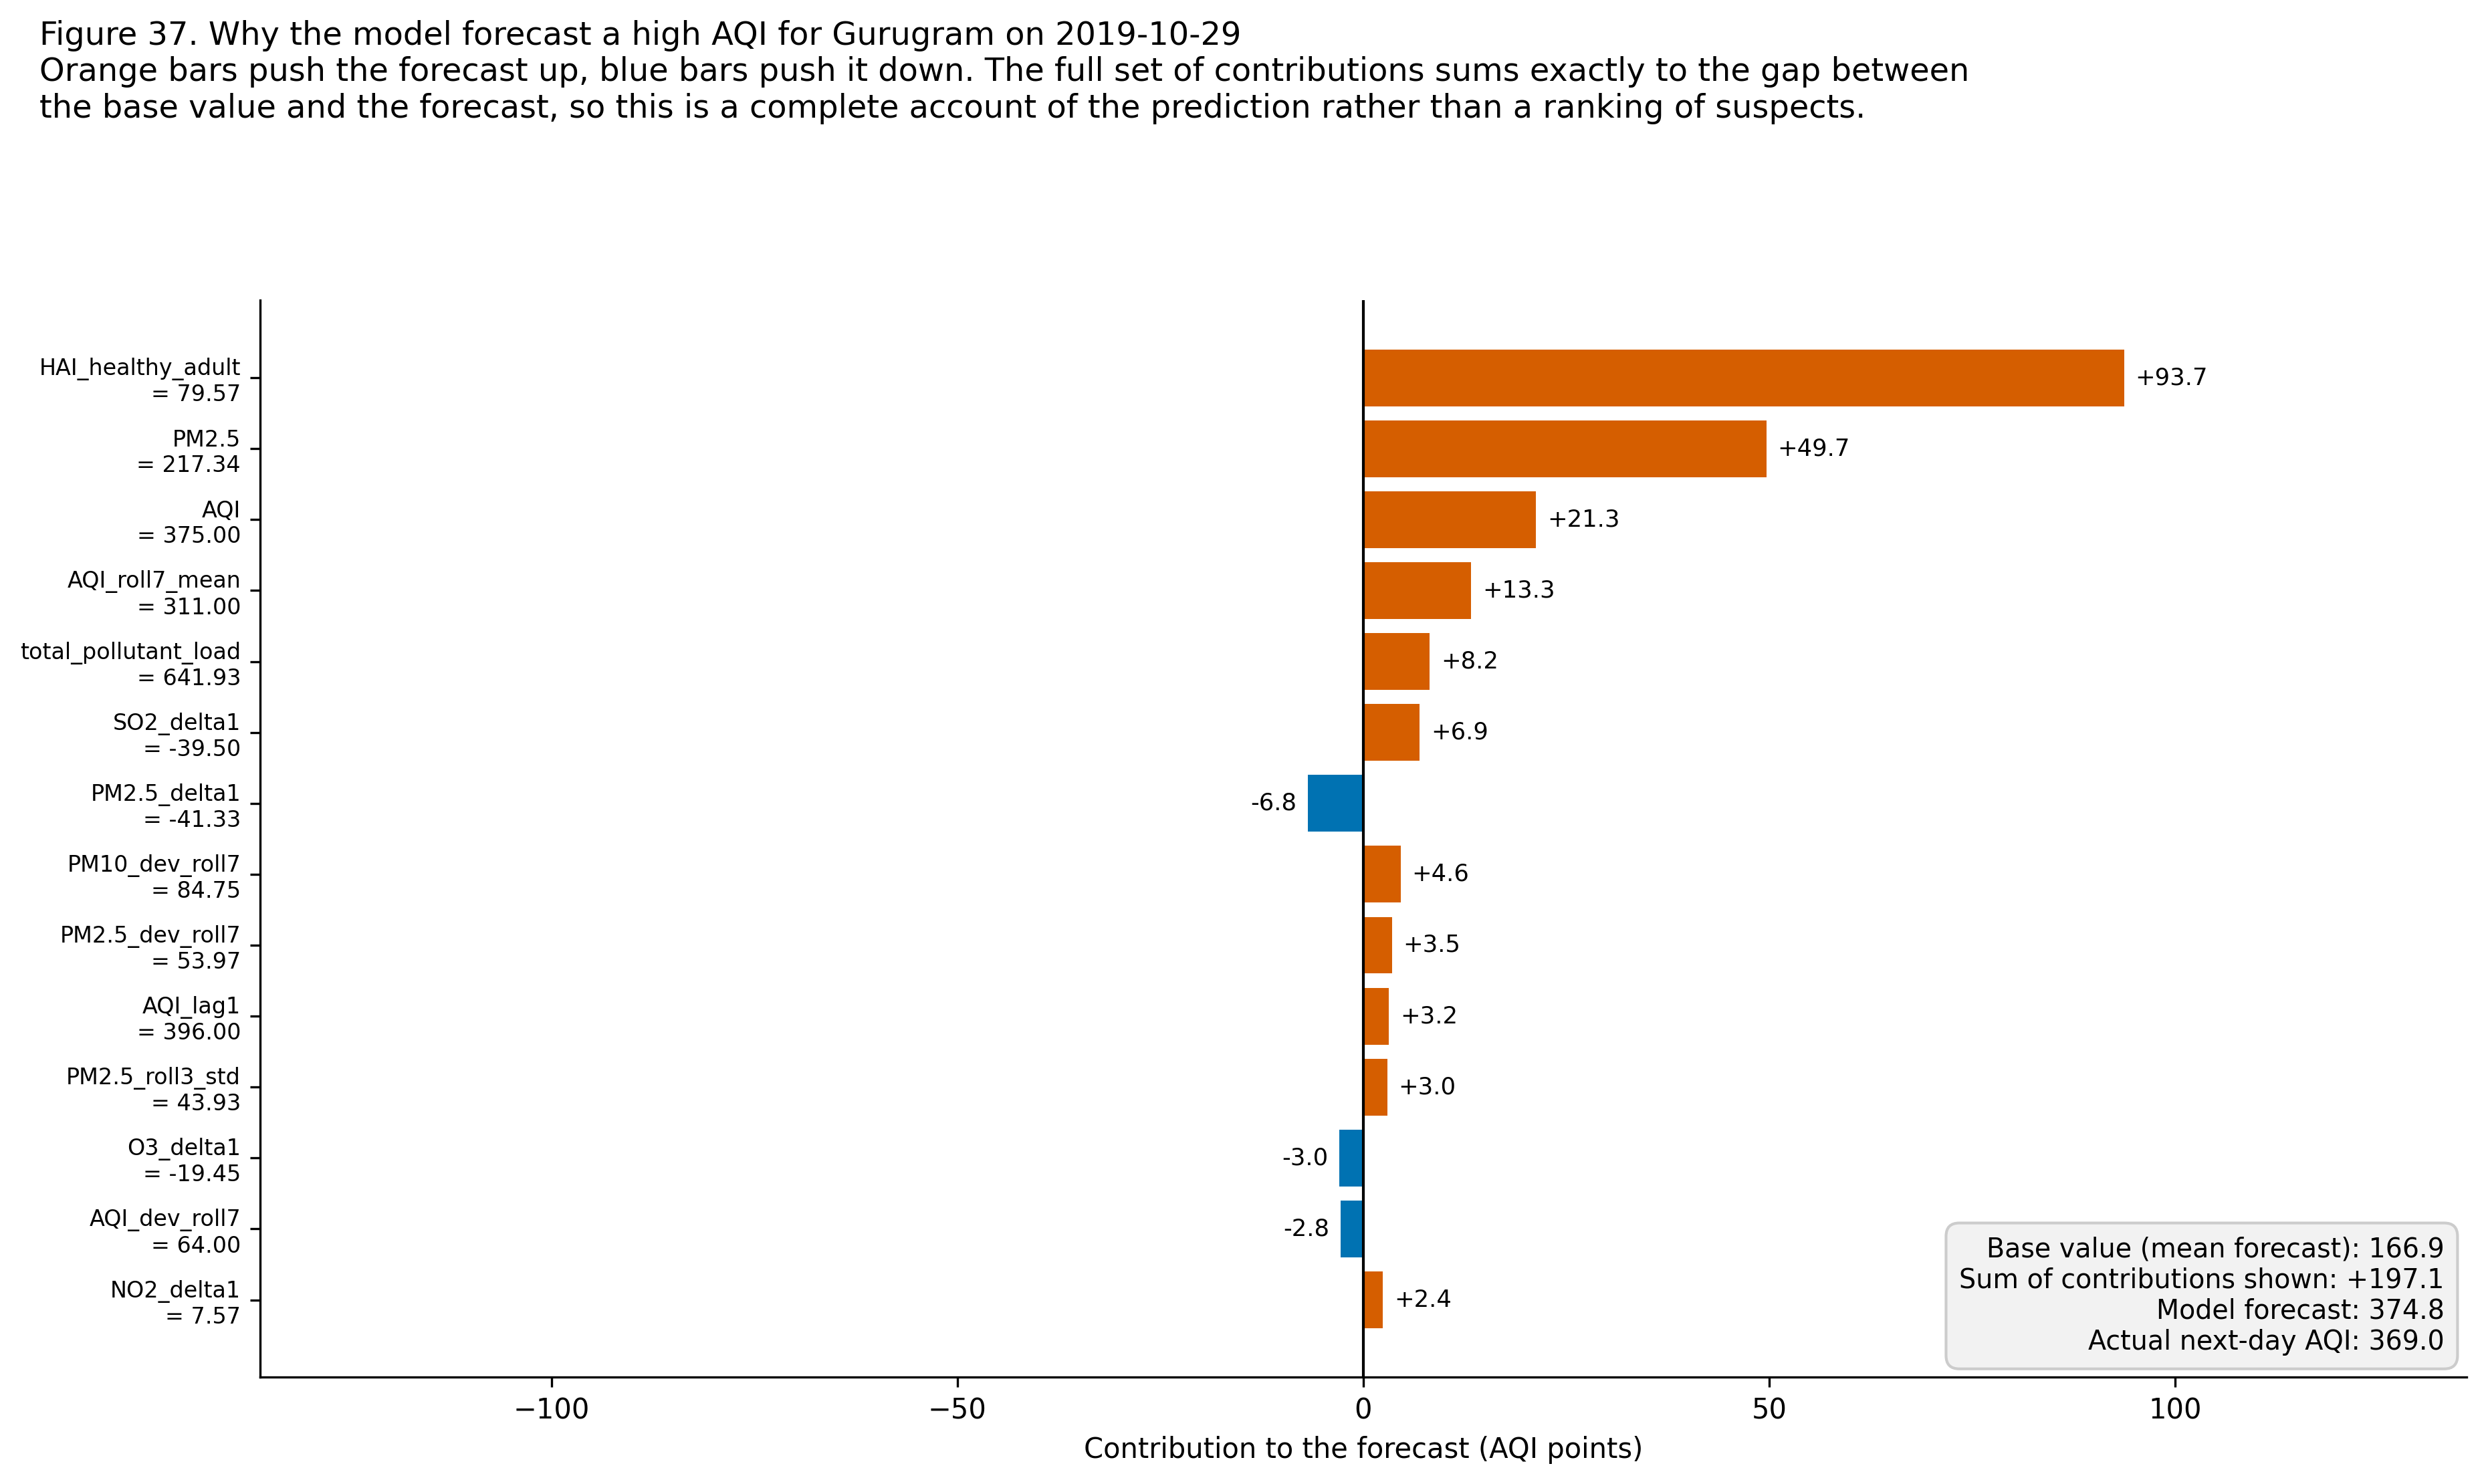

*Figure 11. One high-AQI day, fully decomposed.*

> The global view is dominated by same-day particulate concentration and by short-horizon change features, which is consistent with the exploratory finding that PM2.5 is the strongest single correlate of the AQI and with the strong day-to-day autocorrelation that makes persistence a competitive baseline. The presence of the change and deviation features near the top is the more interesting result: the model is not simply carrying today forward, it is reading the direction and the momentum of the last few days, which is exactly the information the persistence baseline lacks and the source of the margin over it.

In [12]:
explain = load("explainability.json")
display(Markdown(f"**Method.** {explain['method']}"))
show("36_shap_global.png", "Figure 10. Global SHAP explanation of both deployed models.")
show("37_shap_local_waterfall.png", "Figure 11. One high-AQI day, fully decomposed.")
display(Markdown(f"> {explain['interpretation']}"))

## 7. The counterfactual policy simulator

The reduction is an **input**, not a prediction. The simulator states what the advisory burden would be at a given concentration; it does not claim any intervention would achieve it.

> The reduction is an input supplied by the user, not a prediction. The simulator states what the advisory burden would be at a given concentration; it does not claim that any particular intervention would achieve that concentration. Atmospheric chemistry is not simulated: each pollutant is reduced independently, so ozone-led scenarios in particular should be read with caution, because reducing nitrogen oxides can raise local ozone under some urban conditions.

,Scenario,Mean AQI change %,Unsafe days removed %,Advisory-days averted
0,PM2.5 reduced by 10%,-4.48,12.29,4372
1,PM2.5 reduced by 20%,-8.29,25.57,8133
2,PM2.5 and PM10 reduced by 20%,-16.51,29.82,12432
3,PM2.5 and PM10 reduced by 30%,-24.84,42.35,18070
4,NO2 reduced by 30%,-0.06,0.05,243
5,All pollutants reduced by 20%,-17.84,31.55,13413
6,All pollutants reduced by 40%,-36.99,57.96,25461


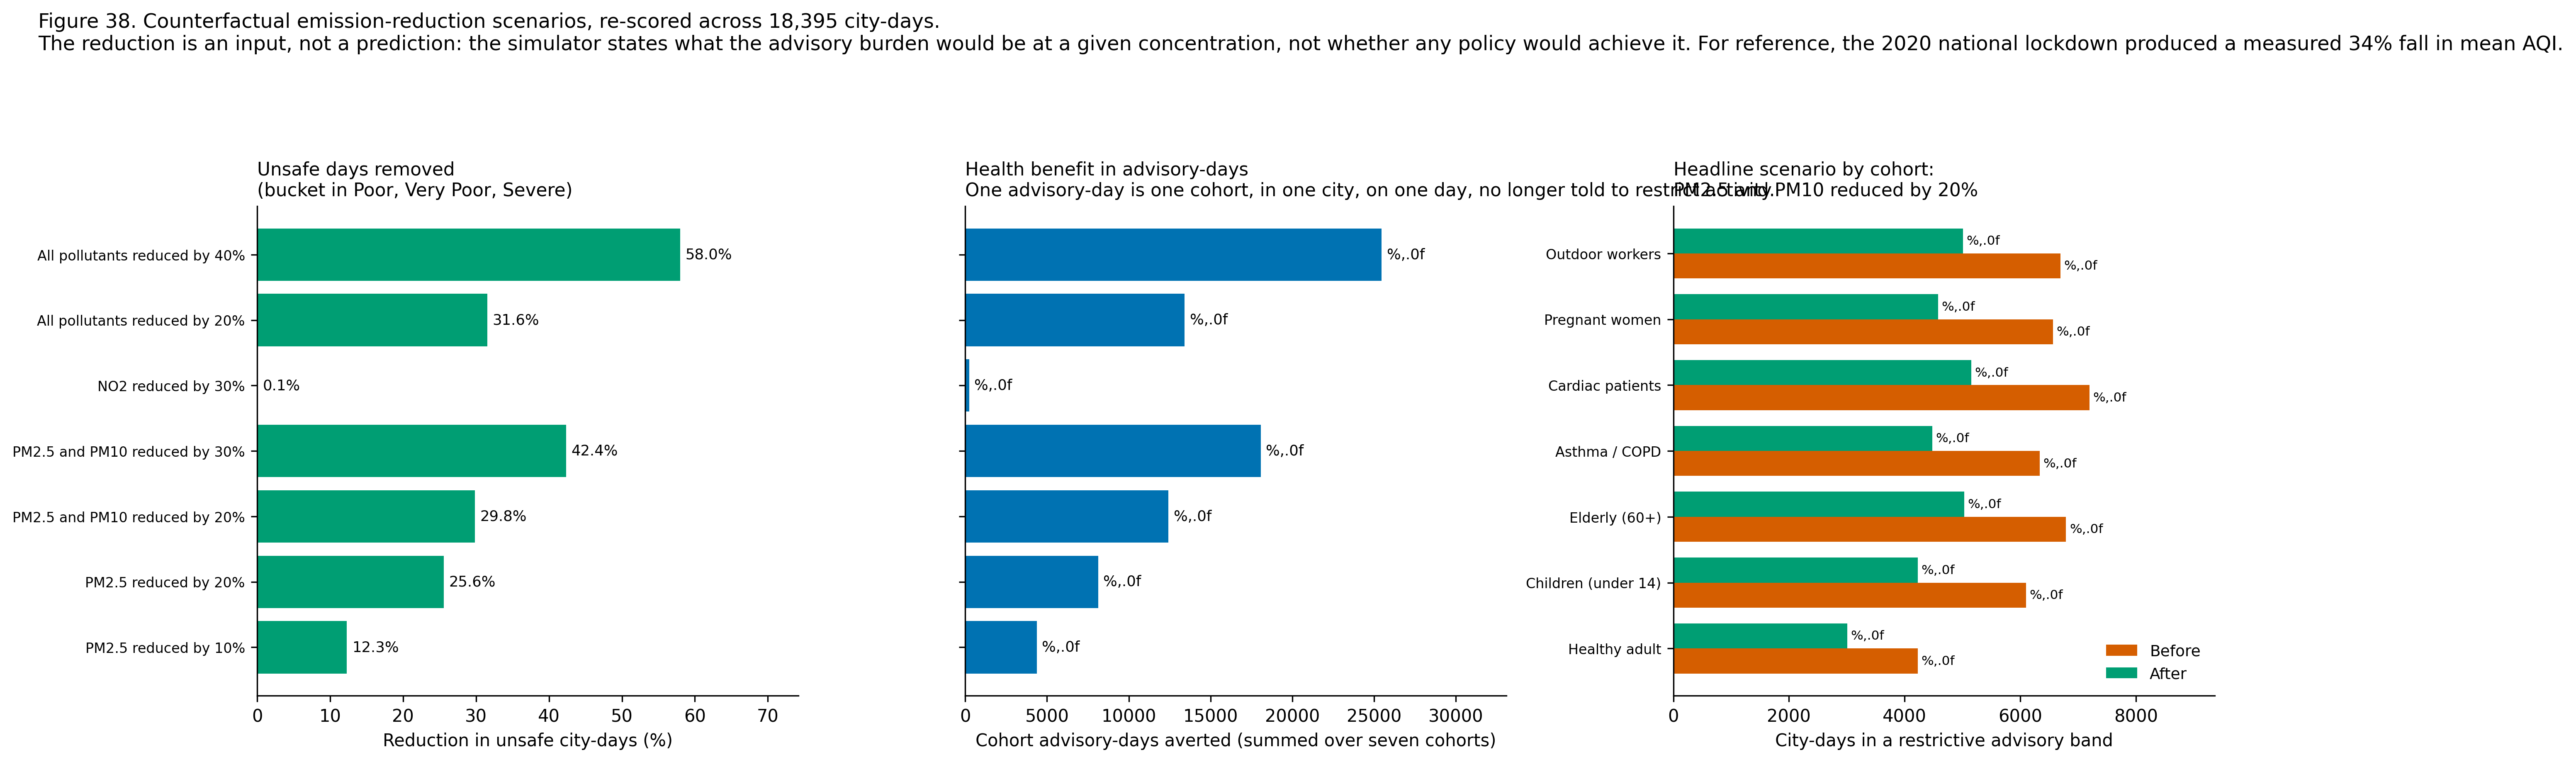

*Figure 12. Counterfactual scenarios and the cohort breakdown.*

In [13]:
policy = load("policy_simulation.json")
display(Markdown(f"> {policy['what_this_is_not']}"))
display(pd.DataFrame([
    {
        "Scenario": s["name"],
        "Mean AQI change %": s["result"]["aqi"]["mean_change_pct"],
        "Unsafe days removed %": s["result"]["unsafe_days"]["reduction_pct"],
        "Advisory-days averted": s["result"]["cohort_advisory_days"]["total_averted_across_cohorts"],
    }
    for s in policy["scenarios"]
]))
show("38_policy_simulation.png", "Figure 12. Counterfactual scenarios and the cohort breakdown.")

In [14]:
anchor = policy.get("lockdown_anchor", {})
whole = next((s for s in policy["scenarios"] if s["name"] == "All pollutants reduced by 40%"), None)
if anchor and whole:
    display(Markdown(
        f"**Sanity check.** The 2020 lockdown produced a measured "
        f"**{anchor['measured_aqi_change_pct']}%** change in national mean AQI. "
        f"The nearest comparable scenario, a 40% reduction across all pollutants, "
        f"yields **{whole['result']['aqi']['mean_change_pct']:+.1f}%**. The two "
        f"agree closely, which is a useful independent check because the simulator "
        f"was not fitted to that episode in any way."
    ))

**Sanity check.** The 2020 lockdown produced a measured **-33.99%** change in national mean AQI. The nearest comparable scenario, a 40% reduction across all pollutants, yields **-37.0%**. The two agree closely, which is a useful independent check because the simulator was not fitted to that episode in any way.

## 8. Final selection

In [15]:
selection = (RESULTS / "final_model_selection.md")
display(Markdown(selection.read_text(encoding="utf-8")))

# Final Model Selection

> Generated by `src/models/evaluate.py` from `results/*.json`. Every figure below was produced by executed code; none is transcribed.

Generated (UTC): 2026-09-29T02:27:43Z

## 1. Regression: next-day AQI value

**Selected model: LightGBM.**

| Criterion | Value |
| --- | --- |
| Primary metric (MAE) | **15.1028** AQI points |
| RMSE | 23.4986 |
| R-squared | 0.9119 |
| MAPE | 14.5791% |
| Median absolute error | 9.7133 |
| Bias | 2.7921 |
| Persistence baseline MAE | 18.9049 |
| Improvement over persistence | **20.11%** |
| Runner-up | Random Forest at MAE 15.2834 |
| Margin over runner-up | 0.181 AQI points |

**Justification.** Mean absolute error is the primary regression metric. The AQI distribution is strongly right-skewed (skewness above 2), so RMSE is dominated by a small number of extreme days and would rank models largely by their behaviour on that tail. MAE is in the same units as the target, is directly interpretable as 'the typical miss in AQI points', and treats every day's error proportionally. RMSE, R-squared and MAPE are reported alongside it, and the tail behaviour that RMSE emphasises is examined separately through the residual analysis and the per-band error breakdown.

LightGBM attains the lowest MAE of the five fitted families and beats the persistence baseline by 20.11%. The margin over Random Forest is 0.181 AQI points, which is small; the selection is therefore additionally supported by its lower RMSE and its shorter fit time. The linear models reach MAE 15.90, so the gain from non-linearity on this problem is real but modest, which is itself a finding worth stating.

### 1.1 Effect of tuning

| | MAE | RMSE | R-squared |
| --- | --- | --- | --- |
| Default parameters | 15.1028 | 23.4986 | 0.9119 |
| Tuned | 15.0488 | 23.413 | 0.9125 |
| Delta | -0.054 | -0.0856 | 0.0006 |

Best parameters: `{"subsample": 0.6, "reg_lambda": 0.1, "reg_alpha": 0.5, "num_leaves": 95, "n_estimators": 400, "min_child_samples": 60, "max_depth": 5, "learning_rate": 0.02, "colsample_bytree": 0.5}`

**Model deployed in the application: LightGBM (tuned).**

## 2. Classification: next-day AQI bucket

**Selected model: XGBoost + SMOTE.**

| Criterion | Value |
| --- | --- |
| Primary metric (macro F1) | **0.7411** |
| Accuracy | 0.7783 |
| Weighted F1 | 0.7794 |
| Balanced accuracy | 0.7453 |
| Cohen's kappa | 0.6648 |
| ROC-AUC (one-versus-rest, macro) | 0.9591 |
| F1 on the Severe class | 0.7595 (support 44) |
| Mean absolute ordinal error | 0.2238 bands |
| Predictions within one band | 99.82% |
| Predictions understating severity | 10.37% |
| Persistence baseline macro F1 | 0.6803 |
| Improvement over persistence | **8.94%** |
| Runner-up | Random Forest + SMOTE at macro F1 0.739 |

**Justification.** Macro-averaged F1 is the primary classification metric, declared before any model was fitted. The six CPCB buckets are imbalanced by a factor of 6.6 between the most and least frequent class, and the rarest classes are Good and Severe. Severe is the class on which the entire public-health purpose of the system rests: failing to warn on a Severe day is the costliest error the system can make, and it is also the error that overall accuracy is least sensitive to. Macro-F1 gives every class equal weight regardless of frequency, so a model cannot score well by ignoring the rare and dangerous classes. Accuracy, weighted F1, per-class F1, balanced accuracy, Cohen's kappa and one-versus-rest ROC-AUC are all reported alongside it, together with an ordinal error that measures how many severity bands a wrong prediction lands away from the truth.

### 2.1 Imbalance remedy, head to head

| Pair | macro F1 (weighted or plain) | macro F1 (SMOTE) | Delta | Winner |
| --- | --- | --- | --- | --- |
| Random Forest vs Random Forest + SMOTE | 0.7184 | 0.739 | +0.0206 | Random Forest + SMOTE |
| XGBoost vs XGBoost + SMOTE | 0.7342 | 0.7411 | +0.0069 | XGBoost + SMOTE |
| Logistic Regression vs Logistic Regression + SMOTE | 0.7236 | 0.7197 | -0.0039 | Logistic Regression |

### 2.2 Effect of tuning

| | macro F1 | Accuracy | Weighted F1 |
| --- | --- | --- | --- |
| Default parameters | 0.7342 | 0.7846 | 0.7809 |
| Tuned | 0.7452 | 0.7933 | 0.7911 |
| Delta | +0.011 | +0.0087 | - |

Best parameters: `{"estimator__subsample": 0.6, "estimator__reg_lambda": 1.0, "estimator__n_estimators": 600, "estimator__min_child_weight": 10, "estimator__max_depth": 10, "estimator__learning_rate": 0.01, "estimator__gamma": 1.0, "estimator__colsample_bytree": 0.7}`

**Model deployed in the application: XGBoost (tuned).**

### 2.3 Safety-relevant error

Of 4,397 test predictions, 975 are wrong (22.17%), but only 8 (0.182%) are wrong by two bands or more, and 5 (0.114%) understate severity by two bands or more. The last figure is the one that matters operationally, because it counts the occasions on which a reader would be told the air is more acceptable than it is.

## 3. Clustering: city pollution archetypes

**Selected: K-Means with k = 2.**

| Criterion | K-Means | Agglomerative (Ward) |
| --- | --- | --- |
| Silhouette | 0.3553 | 0.3553 |
| Davies-Bouldin | 1.0464 | 1.0464 |
| Calinski-Harabasz | 7.2702 | 7.2702 |

Adjusted Rand index between the two partitions: **1.0**. An adjusted Rand index of 1.000 between K-Means and Ward agglomerative clustering indicates that the partition is reproduced almost exactly by an algorithm with a different objective, which is evidence that it reflects structure in the data rather than an artefact of the method.

The rule was fixed before the indices were inspected. Any k whose partition contains a singleton cluster is discarded, because a cluster of one city cannot support a generalisable archetype claim; among the remaining candidates the highest silhouette coefficient decides. Silhouette is the decisive index because it measures separation relative to cohesion and is comparable across k, whereas inertia falls monotonically with k by construction and cannot select k on its own. The four indices do not agree here, and the full vote tally is reported rather than only the winner.

Twelve cities is a small sample for a clustering problem. Silhouette coefficients in the 0.2 to 0.4 range indicate real but moderate separation, and the partition should be read as an interpretive organising device for policy discussion rather than as a claim of sharply bounded natural classes. Every candidate partition is reported below with its scores so that this is visible rather than implied.

### 3.1 Discovered archetypes

| Cluster | Archetype | Defining pollutant | Cities | Policy lever |
| --- | --- | --- | --- | --- |
| 0 | Lower-burden, vehicular NOx led | NO2 | Amaravati, Amritsar, Bengaluru, Chennai, Hyderabad, Jaipur, Kolkata, Thiruvananthapuram, Visakhapatnam | Oxidised nitrogen leads the mix, which is the signature of live traffic exhaust. The effective levers are traffic demand management, public-transport capacity, congestion control at corridors, and tightened in-use vehicle emission testing. |
| 1 | High-burden, fine-particulate led | PM2.5 | Delhi, Gurugram, Lucknow | Fine particulate leads the mix, which points to combustion rather than mechanical sources. The effective levers are fuel-quality and vehicle-fleet standards, control of biomass and solid-fuel burning, and seasonal crop-residue management. |

## 4. Leakage controls, stated and verified

Predicting the same day's bucket with same-day AQI present yields a macro-F1 of 1.0000. A score at or near 1.0 is not a result; it is the signature of a model reading its own label, because the CPCB bucket is a deterministic step function of the AQI. The more instructive finding is what happens after the obvious culprits are removed: dropping AQI, the CPCB sub-indices and every HAI column still leaves macro-F1 at 0.9666. The leak is therefore not confined to a single column that a diligent analyst could blacklist. The AQI is by definition the maximum sub-index, and each sub-index is a fixed piecewise-linear function of a pollutant concentration, so the *concentrations themselves* determine the label exactly. Same-day bucket prediction is arithmetic dressed as machine learning, and no choice of feature filter rescues it. That is the reason this project does not attempt it. Forecasting the next day changes the problem substantively: tomorrow's bucket is genuinely unknown today, today's AQI becomes legitimate information rather than a restatement of the answer, and the achieved macro-F1 of 0.7077 measures real predictive skill. The gap between 0.9666 and 0.7077 is the difference between recomputing a known quantity and forecasting an unknown one.

## 5. Summary

| Task | Selected model | Primary metric | Value | Beats baseline by |
| --- | --- | --- | --- | --- |
| Regression | LightGBM | MAE | 15.1028 | 20.11% |
| Classification | XGBoost + SMOTE | macro F1 | 0.7411 | 8.94% |
| Clustering | K-Means (k=2) | Silhouette | 0.3553 | not applicable (unsupervised) |


## 9. The product

Launch locally with:

```bash
streamlit run app/Home.py
```

Four pages: **Forecast** (cohort-resolved next-day advisory in three languages, with what-if sliders), **City Risk Atlas** (archetypes, seasonality, festival and lockdown panels), **Policy Simulator** (counterfactual re-scoring), and **Model Insights** (comparison tables, SHAP, the leakage demonstration, and the data and model cards).

## 10. Phase 3 outcome

All three learning paradigms trained, tuned, compared and explained; the product shipped; every limitation stated in `reports/model_card.md`.